# Tutorial: K-Means y Hierarchical Clustering 

**SC3314 – Inteligencia Artificial**

**Universidad de Monterrey**


**Jorge Tello 664317**

<div style="page-break-before: always;"></div>


## Índice

**Parte 1 · K-Means desde cero con datos sintéticos**
- 1.1 Dataset
- 1.2 Agrupamiento aleatorio inicial
- 1.3 Centroides
- 1.4 Update
- 1.5 Teoría: K-Means clustering
- 1.6 Iterar hasta converger
- 1.7 Estocasticidad

**Parte 2 · K-Means con datos reales: NCI60**
- 2.1 Dataset
- 2.2 K-Means con scikit-learn
- 2.3 Preprocesamiento con PCA
- 2.4 K-Means con PCA
- 2.5 Interpretación

**Parte 3 · Hierarchical clustering con NCI60**
- 3.1 Dataset y preprocesamiento
- 3.2 Hierarchical clustering: *complete* y euclidiana
- 3.3 Dendrograma
- 3.4 Dendrograma policromático: 2, 3 y 4 clusters
- 3.5 Teoría: altura de corte, jerarquía y algoritmo
- 3.6 Métrica de correlación
- 3.7 Teoría: métricas de disimilitud
- 3.8 Método *average*
- 3.9 Teoría: métodos de linkage

**Parte 4 · K-Means vs hierarchical clustering**
- 4.1 Comparación de resultados en NCI60
- 4.2 Ventajas y desventajas
- 4.3 ¿Cuándo usar cada uno?
- 4.4 ¿Cómo deberían implementarse?

**Conclusiones**

<div style="page-break-before: always;"></div>


## Introducción

En el **aprendizaje no supervisado** se cuenta con observaciones descritas por varias variables, pero sin una variable de respuesta que indique a qué grupo pertenece cada una. El *clustering* busca descubrir esos grupos a partir de los datos mismos, de modo que:

- las observaciones **dentro** de un mismo grupo sean lo más parecidas posible, y
- las observaciones de **grupos distintos** sean lo más diferentes posible.

El tutorial está organizado en cuatro partes:

1. **K-Means desde cero (datos sintéticos).** Se construye el algoritmo paso a paso para entender cómo funciona y por qué su resultado depende de la asignación inicial.
2. **K-Means con datos reales (NCI60).** Se aplica K-Means mediante scikit-learn a datos de expresión génica, se preprocesan los datos con PCA y se interpretan los clusters obtenidos.
3. **Hierarchical clustering (NCI60).** Se construyen dendrogramas y se comparan distintas métricas de disimilitud y métodos de *linkage*.
4. **K-Means vs hierarchical clustering.** Se comparan los resultados de ambos métodos y se discute cuándo conviene usar cada uno.

## Objetivos

Al terminar este tutorial, el lector será capaz de:

- Explicar el funcionamiento de **K-Means** y del **hierarchical clustering**.
- Aplicar K-Means con el **preprocesamiento** necesario.
- Aplicar hierarchical clustering y elegir la cantidad de clusters a partir del **dendrograma**.
- Comprender las diferentes **funciones de linkage** y **métricas de disimilitud**.
- **Interpretar** los clusters generados.

Todo el código se puede ejecutar en Google Colab de principio a fin. Las semillas aleatorias están fijas, así que los resultados coinciden con los descritos en el texto, sin embargo, sientase libre de modificar el codigo y ajustarlo a sus semilla de preferencia de modo que pueda comprender de mejor manera su funcionamiento si así lo desea.

## Librerias Utilizadas

- `numpy` y `pandas` para manejar los datos.
- `matplotlib` y `seaborn` para las gráficas.
- `scikit-learn` para generar el dataset sintético, K-Means, estandarización y PCA.
- `scipy` para el hierarchical clustering y los dendrogramas.
- `ISLP` para cargar el dataset NCI60.

### Instalación de dependencias

El dataset NCI60 se encuentra en la librería `ISLP`, que no viene preinstalada en Colab. La siguiente celda la instala (el símbolo `!` ejecuta un comando de terminal y `-q` oculta el registro de instalación).

In [1]:
%%capture
!pip install ISLP -q

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, dendrogram
from ISLP import load_data

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
colores = np.array(sns.color_palette('tab10'))

<div style="page-break-before: always;"></div>

---
# Parte 1 · K-Means desde cero con datos sintéticos

## 1.1 Dataset

Para entender el algoritmo empezamos con un dataset **sintético**, generado con la función `make_blobs()`. Como nosotros definimos cuántos grupos tiene, podemos comprobar después si el algoritmo los encuentra. Usamos:

| Parámetro | Valor |
|---|---|
| Muestras (`n_samples`) | 1000 |
| Centros (`centers`) | 3 |
| Variables (`n_features`) | 2 |
| Desviación estándar (`cluster_std`) | 1.5 |

`make_blobs` también devuelve la etiqueta con la que se creó cada punto. **No la incluimos en la gráfica**, porque en un problema de clustering esa información no existe, el algoritmo debe descubrir los grupos sin ella.

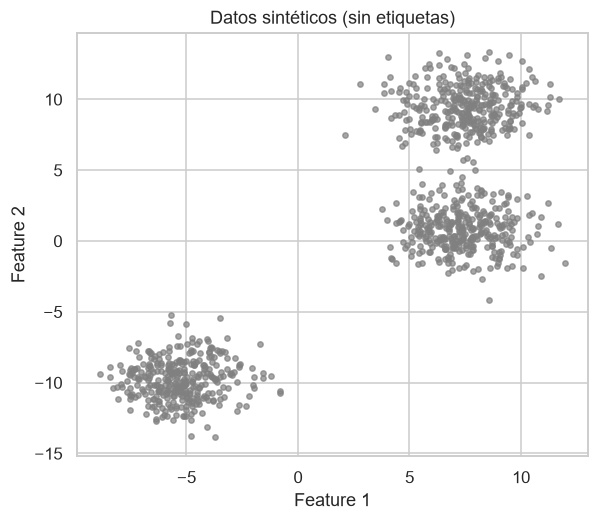

In [23]:
X, _ = make_blobs(n_samples=1000, centers=3, n_features=2, cluster_std=1.5, random_state=8)
df = pd.DataFrame(X, columns=['feature_1', 'feature_2'])

plt.figure(figsize=(6, 5))
plt.scatter(df.feature_1, df.feature_2, s=12, color='gray', alpha=0.7)
plt.xlabel('Feature 1'); plt.ylabel('Feature 2')
plt.title('Datos sintéticos (sin etiquetas)')
plt.show()

**¿Qué muestra la gráfica?** 

A simple vista se distinguen tres nubes de puntos. El algoritmo no "ve" la gráfica, solo tiene las coordenadas. Lo que queremos es que distinga esos tres "grupos" por sí solo.

## 1.2 Agrupamiento aleatorio inicial

K-Means necesita un punto de partida, así que asignamos de forma aleatoria cada observación a uno de los $K = 3$ clusters. Usamos una semilla para que la asignación sea reproducible, en este caso se usará 61.

La etiqueta de cada observación se guarda en la columna `cluster` del DataFrame. En las gráficas, esa etiqueta se representa con el **color** del punto, y la leyenda indica a qué cluster corresponde cada color.

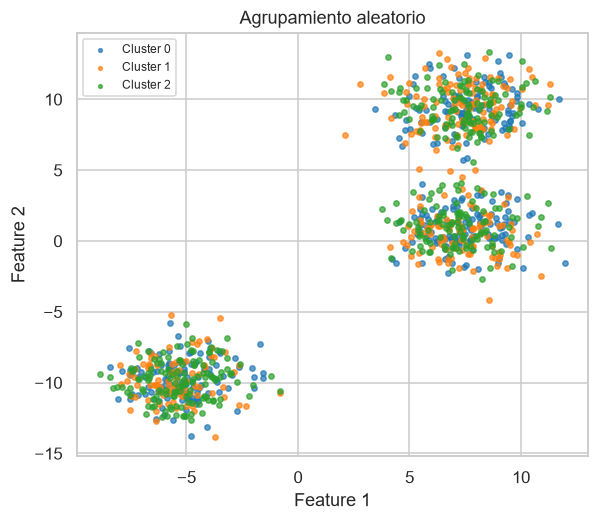

cluster
0    334
1    304
2    362
Name: count, dtype: int64


In [24]:
K = 3
rng = np.random.default_rng(61)
df['cluster'] = rng.integers(0, K, size=len(df))

def graficar(df, C=None, titulo='', ax=None):
    ax = ax or plt.figure(figsize=(6, 5)).gca()
    for k in sorted(df.cluster.unique()):
        m = df.cluster == k
        ax.scatter(df.feature_1[m], df.feature_2[m], s=12, alpha=0.7, color=colores[k], label=f'Cluster {k}')
    if C is not None:
        ax.scatter(C[:, 0], C[:, 1], s=250, marker='X', c=colores[:len(C)],
                   edgecolor='black', linewidth=1.5, label='Centroides')
    ax.set_xlabel('Feature 1'); ax.set_ylabel('Feature 2'); ax.set_title(titulo)
    ax.legend(fontsize=8, markerscale=0.7, loc='best')
    return ax

graficar(df, titulo='Agrupamiento aleatorio')
plt.show()
print(df.cluster.value_counts().sort_index())

**¿Qué indica?** 

Los colores están completamente mezclados. Cada cluster tiene aproximadamente un tercio de las observaciones, pero ninguno corresponde a una de las nubes, se observa que todavía no hay grupos con sentido. Este es el estado inicial que el algoritmo irá mejorando.

## 1.3 Centroides

El **centroide** de un cluster es el vector que contiene la media de cada variable para las observaciones de ese cluster. En este caso, cada centroide tiene dos valores, la media de `feature_1` y la media de `feature_2`.

   feature_1  feature_2
0      3.304      0.005
1      3.722      0.976
2      2.675     -0.349


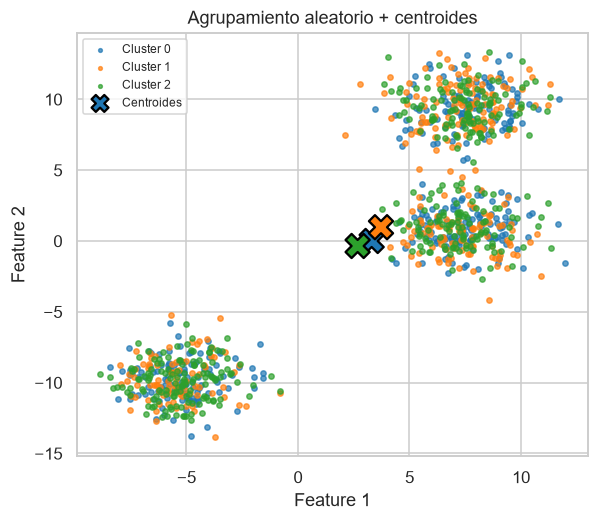

In [25]:
def calcular_centroides(df, K, C_prev=None):
    C = df.groupby('cluster')[['feature_1', 'feature_2']].mean().reindex(range(K)).to_numpy(copy=True)
    if C_prev is not None:                      # si un cluster se queda sin observaciones, conserva su centroide anterior
        vacios = np.isnan(C).any(axis=1)
        C[vacios] = C_prev[vacios]
    return C

C = calcular_centroides(df, K)
print(pd.DataFrame(C, columns=['feature_1', 'feature_2']).round(3))

graficar(df, C, 'Agrupamiento aleatorio + centroides')
plt.show()

**¿Qué indica?** 

Como la asignación fue aleatoria, cada cluster contiene puntos de las tres nubes, y su media queda cerca del **centro de todos los datos**. Por eso los tres centroides aparecen casi encimados. Aun así no son idénticos, y esa pequeña diferencia es suficiente para que el siguiente paso empiece a separar los grupos.

## 1.4 Update

El update consiste en:

1. **Etiquetar nuevamente** cada observación, haciendola pertenece al cluster cuyo centroide está **más cercano**, usando la distancia euclidiana.
2. **Calcular los nuevos centroides** con las nuevas etiquetas.

El código está escrito para que este paso se pueda **iterar**: la función actualiza el mismo DataFrame en lugar de crear uno nuevo, así que puede llamarse una y otra vez. Además, si algún cluster se queda sin observaciones, `calcular_centroides` conserva su centroide anterior para que el proceso pueda continuar.

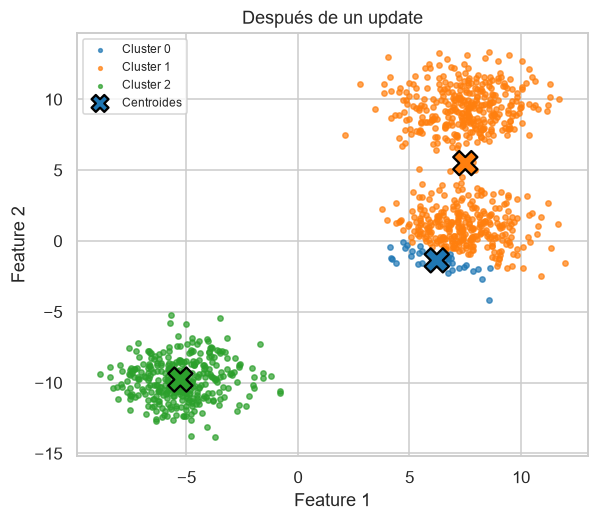

cluster
0     35
1    632
2    333
Name: count, dtype: int64


In [26]:
def actualizar(df, C, K):
    Xv = df[['feature_1', 'feature_2']].to_numpy()
    distancias = ((Xv[:, None, :] - C[None, :, :]) ** 2).sum(axis=2)   # distancia euclidiana (al cuadrado) a cada centroide
    df['cluster'] = distancias.argmin(axis=1)                           # cluster más cercano
    return df, calcular_centroides(df, K, C)

df, C = actualizar(df, C, K)
graficar(df, C, 'Después de un update')
plt.show()
print(df.cluster.value_counts().sort_index())

**¿Qué indica?** 

Con **un solo update** el cambio es enorme, los puntos ya no están mezclados al azar y las fronteras entre colores son rectas, porque cada punto se asigna al centroide más cercano.

Sin embargo, la partición todavía no es buena. Como los tres centroides iniciales estaban casi encimados, uno de ellos se quedó con las dos nubes de la derecha completas, otro con la nube de abajo a la izquierda, y el tercero apenas capturó unas decenas de puntos en el borde inferior de la nube central. Hace falta repetir el update.

## 1.5 Teoría: K-Means clustering

Un "buen" agrupamiento es aquel para el que la **variación dentro del grupo** $W(C_k)$ es tan pequeña como sea posible. $W(C_k)$ mide la magnitud en que las observaciones dentro de un grupo difieren entre sí. K-Means busca:

$$\underset{C_1,\dots,C_K}{\text{minimize}} \left\{ \sum_{k=1}^{K} W(C_k) \right\}$$

### Variación dentro del grupo (*within-cluster variation*)

Usamos la **distancia euclidiana al cuadrado**:

$$W(C_k) = \frac{1}{|C_k|} \sum_{i,i' \in C_k} \sum_{j=1}^{p} (x_{ij} - x_{i'j})^2$$

Elevar la distancia al cuadrado tiene tres ventajas:

- Permite usar promedios en vez de medianas para los centroides (de ahí el nombre *K-means* y no *K-medians*).
- El cálculo se convierte en una multiplicación de matrices simple.
- Enfatiza las desviaciones grandes.

La fórmula compara todos los pares de observaciones del cluster, lo que tiene un costo $\mathcal{O}(n^2)$. Las implementaciones nuevas calculan la diferencia de cada observación **contra el centroide**, con costo $\mathcal{O}(n)$.

### Algoritmo (óptimo local)

1. Asignar aleatoriamente un número, de 1 a $K$, a cada observación.
2. Iterar hasta que las asignaciones de cluster dejen de cambiar:
   - **a)** Para cada cluster, calcular el centroide: el vector de los promedios de las $p$ variables para las observaciones del cluster.
   - **b)** Asignar cada observación al cluster cuyo centroide es más cercano (distancia euclidiana al cuadrado).

Los pasos 1.2, 1.3 y 1.4 son exactamente este algoritmo. Ahora solo falta repetir el update hasta que las etiquetas dejen de cambiar.

## 1.6 Iterar hasta converger

Juntamos todo en una función. En cada iteración calculamos también el objetivo $\sum_k W(C_k)$ con la fórmula de la sección anterior, para ver cómo cambia.

Convergió en 5 iteraciones


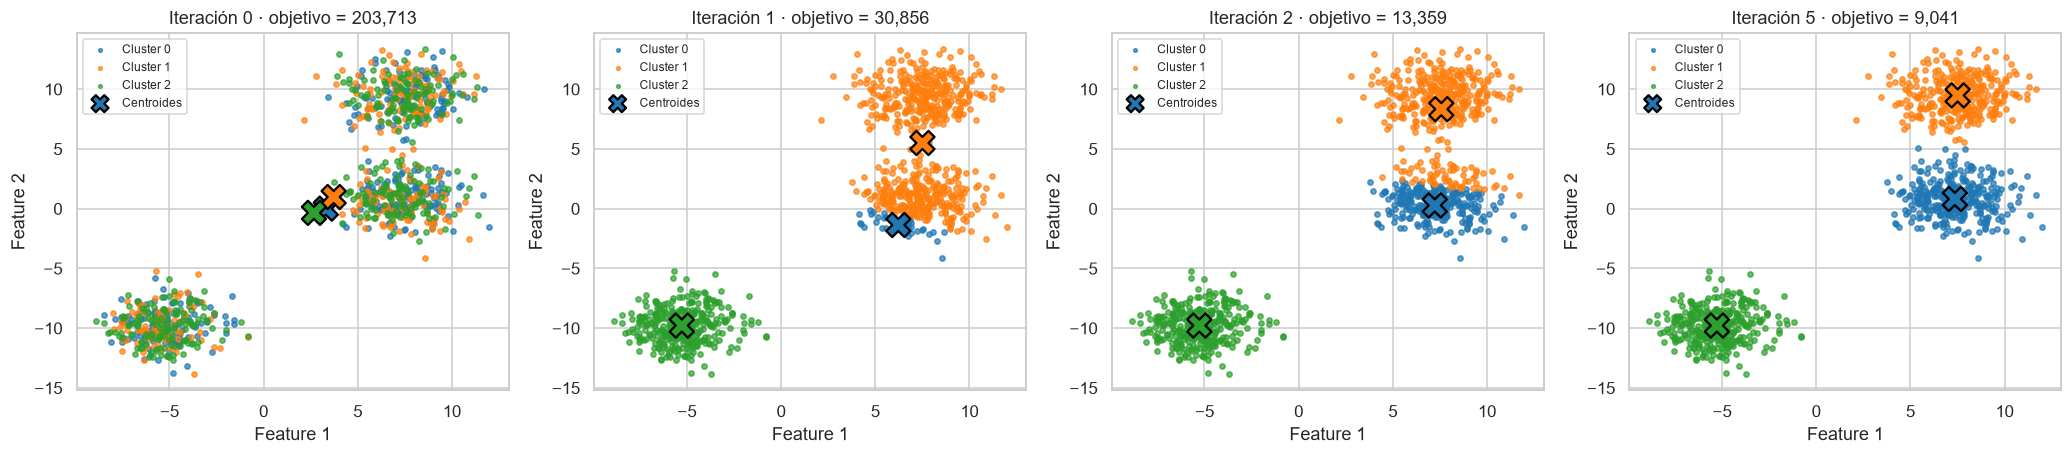

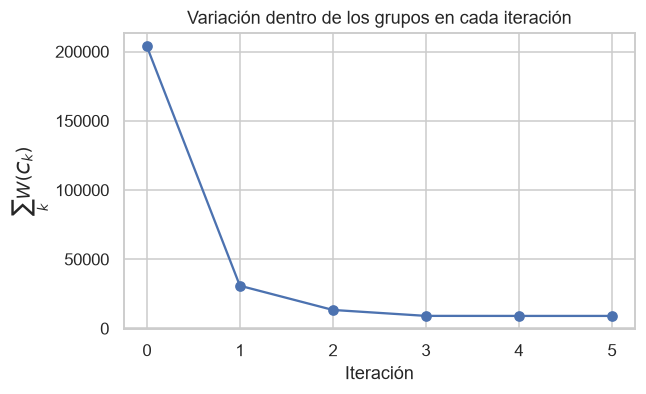

In [27]:
def objetivo(df, K):
    Xv = df[['feature_1', 'feature_2']].to_numpy()
    total = 0
    for k in range(K):
        Xk = Xv[df.cluster == k]
        if len(Xk) > 0:
            total += ((Xk[:, None, :] - Xk[None, :, :]) ** 2).sum() / len(Xk)   # W(C_k)
    return total

def kmeans_manual(X, K, seed=None, max_iter=100):
    d = pd.DataFrame(X, columns=['feature_1', 'feature_2'])
    d['cluster'] = np.random.default_rng(seed).integers(0, K, size=len(d))   # paso 1: asignación aleatoria
    C = calcular_centroides(d, K)
    historia = [(d.cluster.copy(), C.copy(), objetivo(d, K))]
    for _ in range(max_iter):                                                 # paso 2: iterar
        previas = d.cluster.copy()
        d, C = actualizar(d, C, K)
        historia.append((d.cluster.copy(), C.copy(), objetivo(d, K)))
        if (d.cluster == previas).all():                                      # las asignaciones dejaron de cambiar
            break
    return d, C, historia

df, C, historia = kmeans_manual(X, K, seed=61)
print(f'Convergió en {len(historia) - 1} iteraciones')

pasos = [0, 1, 2, len(historia) - 1]
fig, axs = plt.subplots(1, 4, figsize=(19, 4.3))
for ax, p in zip(axs, pasos):
    etiquetas_p, Cp, obj = historia[p]
    graficar(pd.DataFrame({'feature_1': X[:, 0], 'feature_2': X[:, 1], 'cluster': etiquetas_p}),
             Cp, f'Iteración {p} · objetivo = {obj:,.0f}', ax)
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 3.5))
plt.plot([h[2] for h in historia], 'o-')
plt.xlabel('Iteración'); plt.ylabel(r'$\sum_k W(C_k)$')
plt.title('Variación dentro de los grupos en cada iteración'); plt.show()

**¿Qué indican los resultados?**

- En la **iteración 1** dos nubes comparten un solo cluster y el tercer cluster apenas tiene unos cuantos puntos en el borde de la nube central. En la **iteración 2** el centroide de ese cluster ya se metió en la nube central y le disputa los puntos al otro cluster. Desde ahí el algoritmo solo afina las fronteras, hasta que en la **iteración 5** las etiquetas dejan de cambiar.
- La variación dentro de los grupos baja en cada iteración: cae drásticamente al principio y después se ajusta poco. Es lo que busca K-Means: minimizar $\sum_k W(C_k)$.
- Al converger, cada centroide está en el centro de una nube y los colores coinciden con los tres grupos que se veían a simple vista en el dataset.

## 1.7 Estocasticidad

Regresamos al punto en que definimos de forma aleatoria el cluster de cada observación, **eliminamos la semilla** (`seed=None`) y volvemos a correr el proceso:

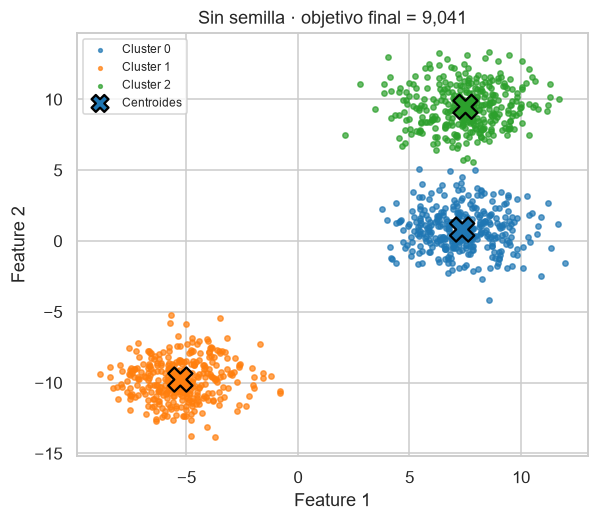

In [43]:
df_sin_semilla, C_sin_semilla, hist_sin_semilla = kmeans_manual(X, K, seed=None)
graficar(df_sin_semilla, C_sin_semilla, f'Sin semilla · objetivo final = {hist_sin_semilla[-1][2]:,.0f}')
plt.show()

Sin semilla, cada ejecución de la celda anterior parte de una asignación inicial distinta, así que el resultado puede cambiar entre ejecuciones: a veces solo cambia qué color recibe cada grupo, y otras veces cambia la partición.

Para mostrarlo de forma reproducible, corremos el proceso desde **6 asignaciones iniciales distintas** (semillas 0 a 5) y comparamos el objetivo final de cada una:

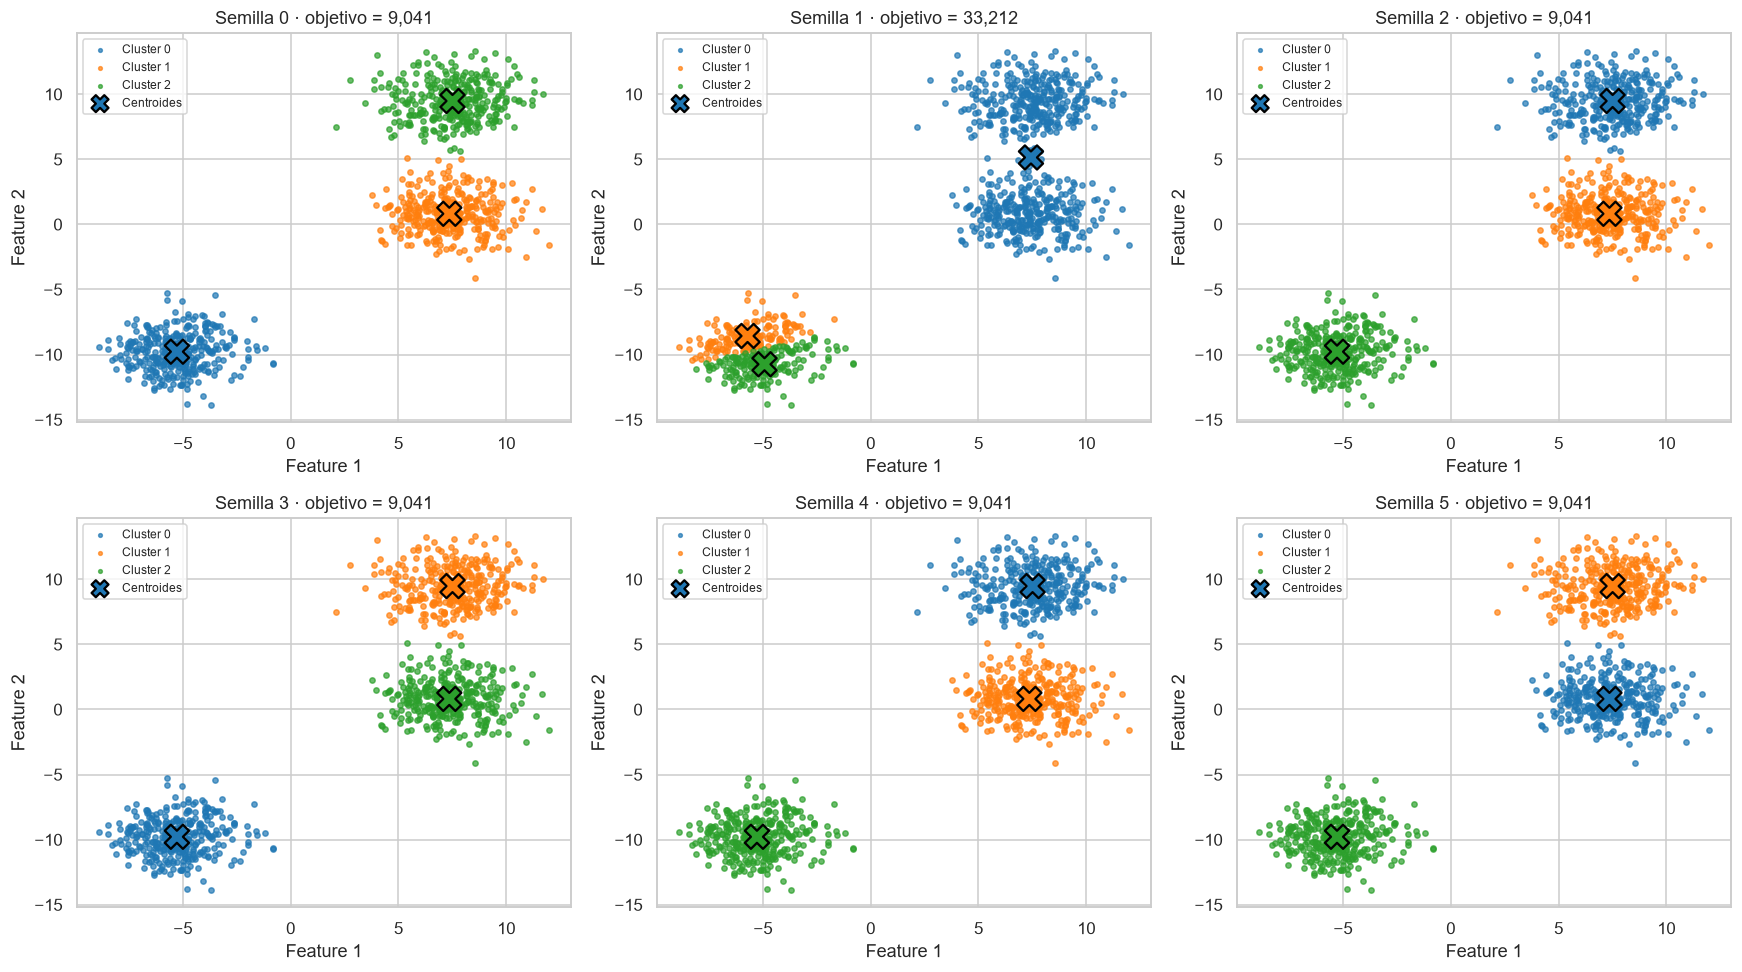

In [44]:
fig, axs = plt.subplots(2, 3, figsize=(16, 9))
for s, ax in zip(range(6), axs.ravel()):
    d, Cs, h = kmeans_manual(X, K, seed=s)
    graficar(d, Cs, f'Semilla {s} · objetivo = {h[-1][2]:,.0f}', ax)
plt.tight_layout(); plt.show()

**¿Qué indica?**

- Cinco de las seis inicializaciones llegan a la misma solución (objetivo ≈ 9,041), la que recupera las tres nubes.
- La **semilla 1** llega a una solución distinta y mucho peor (objetivo ≈ 33,212), pues junta dos nubes en un solo cluster y parte la tercera en dos. Una vez ahí, las etiquetas dejan de cambiar y el algoritmo se detiene, aunque la solución no sea la mejor.

Esto ocurre porque el algoritmo encuentra un **óptimo local**, y ese óptimo depende de la asignación aleatoria inicial: diferentes asignaciones iniciales pueden generar diferentes resultados. Por eso, típicamente:

- se corre el algoritmo **múltiples veces**, cada vez desde una asignación inicial distinta, y
- se selecciona la **mejor solución**: la que tiene el **objetivo más pequeño**.

En la siguiente parte usaremos la función `KMeans` de scikit-learn, donde esto se controla con el parámetro `n_init`.

<div style="page-break-before: always;"></div>

---
# Parte 2 · K-Means con datos reales: NCI60

## 2.1 Dataset

Usamos el dataset **NCI60** de la librería `ISLP`. Cada observación es una línea celular de cáncer y cada variable es la medición de expresión de un gen. Además, cada observación tiene una etiqueta con su tipo de cáncer. Igual que en la Parte 1, **no usaremos las etiquetas para agrupar** y solo las usaremos al final para interpretar los clusters.

Revisamos sus características, la forma (`shape`) y la cantidad de observaciones de cada etiqueta.

In [ ]:
nci = load_data('NCI60')
datos = nci['data']
etiquetas = nci['labels']['label']

print('Shape:', datos.shape)
print('\nObservaciones por etiqueta:')
print(etiquetas.value_counts())

Shape: (64, 6830)

Observaciones por etiqueta:
label
RENAL          9
NSCLC          9
MELANOMA       8
BREAST         7
COLON          7
OVARIAN        6
LEUKEMIA       6
CNS            5
PROSTATE       2
UNKNOWN        1
K562B-repro    1
K562A-repro    1
MCF7A-repro    1
MCF7D-repro    1
Name: count, dtype: int64


**¿Qué indica?**

- El dataset tiene **64 observaciones** (líneas celulares) y **6,830 variables** (genes), es decir, hay muchas más variables que observaciones.
- Hay 14 etiquetas distintas y muy desbalanceadas. Algunas tienen hasta 9 observaciones y otras solo 1 (por ejemplo, `UNKNOWN` y las que terminan en `-repro`).

## 2.2 K-Means con scikit-learn

Aplicamos la función `KMeans` de scikit-learn directamente a los 6,830 genes:

- `n_clusters=4`: dentro del rango de 3 a 5 clusters.
- `n_init=20`: el algoritmo se corre 20 veces con distintas asignaciones iniciales y se queda con la mejor solución, como vimos en la sección 1.7.

Para visualizar los clusters graficamos algunos pares de variables. Elegimos los 3 genes con mayor varianza.

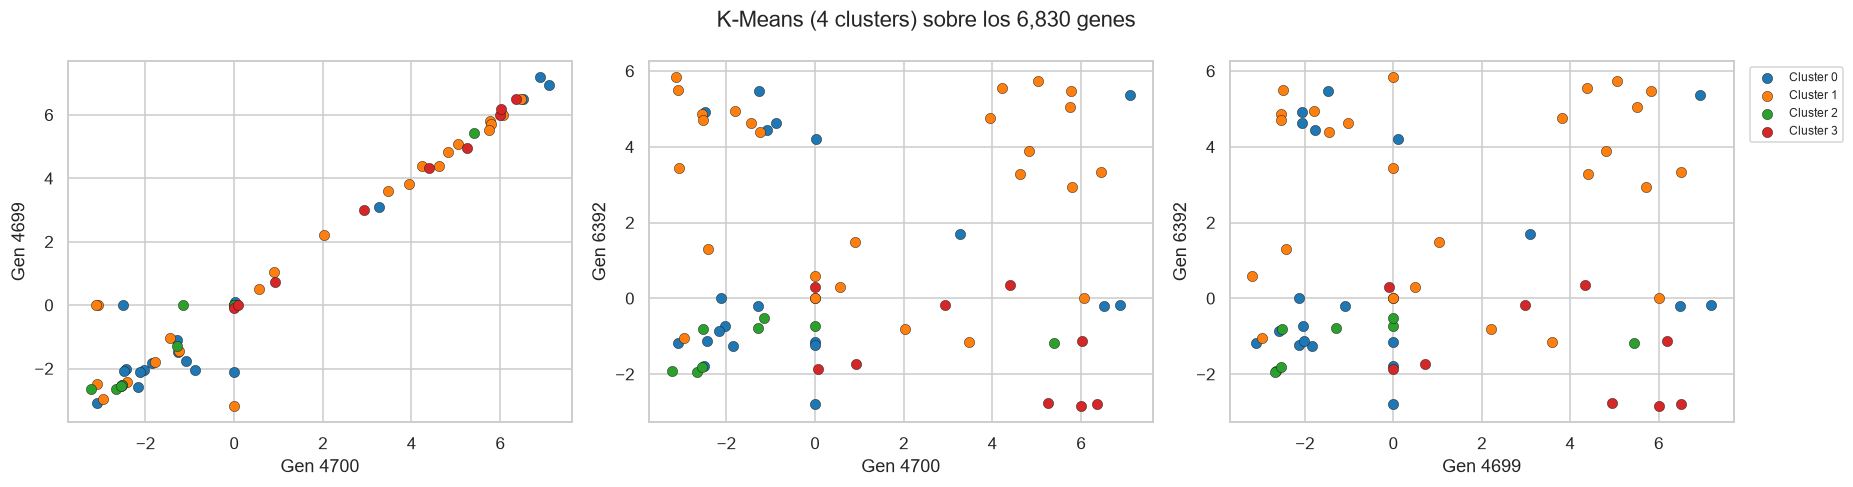

Observaciones por cluster: [20 27  8  9]


In [31]:
km_crudo = KMeans(n_clusters=4, n_init=20, random_state=0).fit(datos)

top_var = np.argsort(datos.var(axis=0))[::-1][:3]
pares = [(0, 1), (0, 2), (1, 2)]

def graficar_pares(Xp, etiquetas_cl, nombres, titulo, centros=None):
    fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))
    for ax, (a, b) in zip(axs, pares):
        for k in np.unique(etiquetas_cl):
            m = etiquetas_cl == k
            ax.scatter(Xp[m, a], Xp[m, b], s=45, color=colores[k], edgecolor='k', linewidth=0.3, label=f'Cluster {k}')
        if centros is not None:
            ax.scatter(centros[:, a], centros[:, b], marker='X', s=250, c=colores[:len(centros)],
                       edgecolor='k', linewidth=1.5, label='Centroides')
        ax.set_xlabel(nombres[a]); ax.set_ylabel(nombres[b])
    axs[-1].legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
    fig.suptitle(titulo); plt.tight_layout(); plt.show()

graficar_pares(datos[:, top_var], km_crudo.labels_, [f'Gen {g}' for g in top_var],
               'K-Means (4 clusters) sobre los 6,830 genes')
print('Observaciones por cluster:', np.bincount(km_crudo.labels_))

**¿Qué indica?** 

En los pares de genes los colores aparecen mezclados. Esto no significa que el algoritmo haya fallado:, sino que los clusters se formaron usando las 6,830 variables, y cada gráfica muestra solo 2 de ellas. El problema es que así no podemos visualizar ni interpretar los clusters.

También se nota que dos de estos genes (primera gráfica) están casi perfectamente relacionados entre sí, es decir, aportan prácticamente la misma información. Con tantas variables, muchas son redundantes. Esto nos indica que hace falta un preprocesamiento.

## 2.3 Preprocesamiento con PCA

Usamos **PCA** para transformar los datos. PCA construye nuevas variables, los componentes principales (PCs), que son combinaciones de los genes ordenadas según la cantidad de varianza que explican. Con los primeros componentes podemos resumir los datos en pocas dimensiones, visualizarlos y agruparlos.

Antes de aplicar PCA estandarizamos cada gen (media 0 y desviación estándar 1), para que ningún gen domine los componentes solo por tener valores más grandes.

Primero graficamos PC1 vs PC2, PC1 vs PC3 y PC2 vs PC3 para ver si se distinguen grupos.

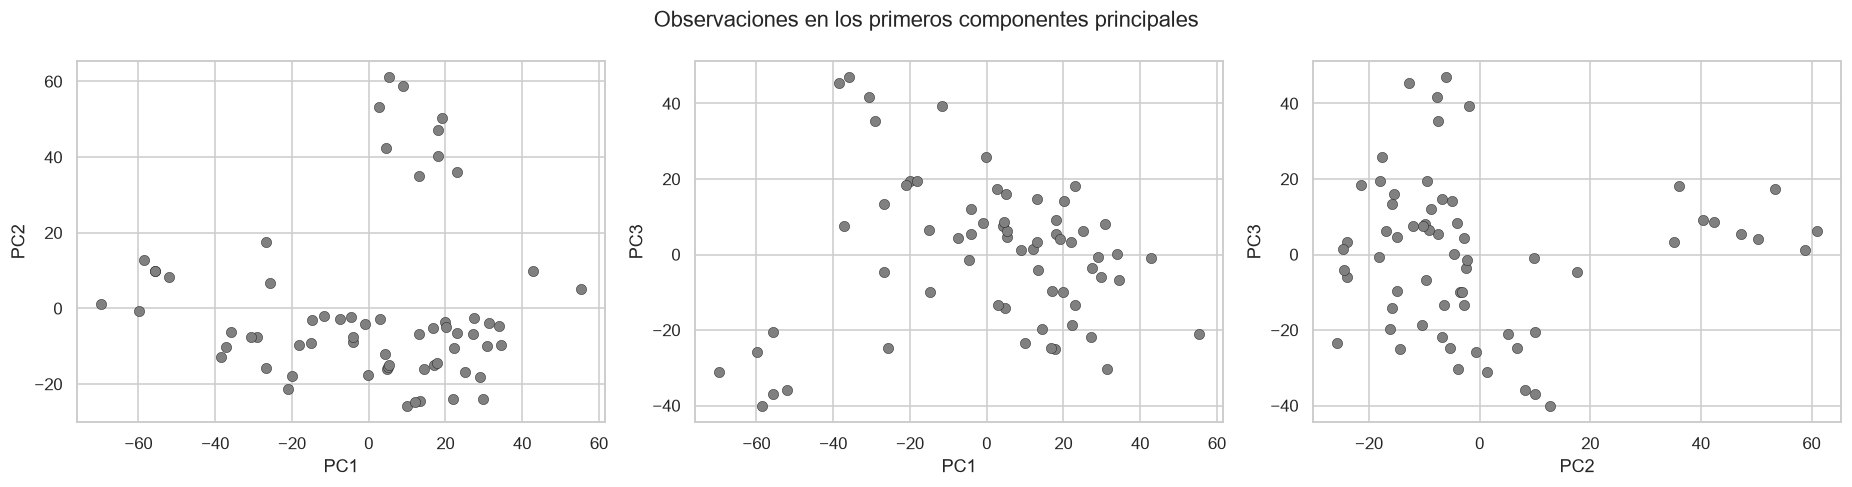

In [32]:
datos_esc = StandardScaler().fit_transform(datos)
pca = PCA().fit(datos_esc)
scores = pca.transform(datos_esc)

fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (a, b) in zip(axs, pares):
    ax.scatter(scores[:, a], scores[:, b], s=45, color='gray', edgecolor='k', linewidth=0.3)
    ax.set_xlabel(f'PC{a+1}'); ax.set_ylabel(f'PC{b+1}')
fig.suptitle('Observaciones en los primeros componentes principales')
plt.tight_layout(); plt.show()

**¿Qué indica?** 

A diferencia de los pares de genes, aquí sí se distinguen grupos:

- En **PC1 vs PC2** se separan dos grupos pequeños del resto: uno hacia la izquierda (PC1 muy negativo) y otro hacia arriba (PC2 alto).
- En **PC1 vs PC3** aparece un tercer grupo hacia arriba (PC3 alto) que en PC1 vs PC2 quedaba encimado con el resto.
- El resto de las observaciones forma una nube central.

### Cantidad de clusters

Con base en estas gráficas determinamos **4 clusters**, los tres grupos que se separan en alguna combinación de componentes, más la nube central. Este valor está dentro del rango de 3 a 5 clusters.

### Varianza explicada

Graficamos la varianza que explica cada componente y la varianza acumulada, para determinar cuántos componentes principales usar.

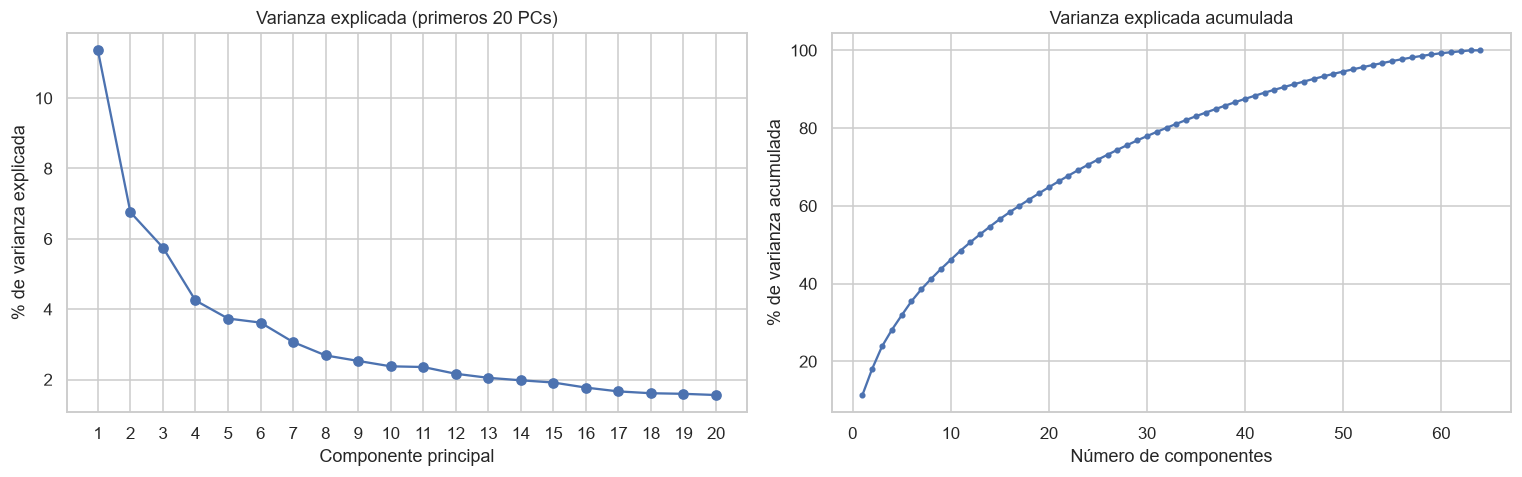

      % varianza  % acumulado
PC1        11.36         11.4
PC2         6.76         18.1
PC3         5.75         23.9
PC4         4.25         28.1
PC5         3.73         31.8
PC6         3.62         35.5
PC7         3.07         38.5
PC8         2.69         41.2
PC9         2.53         43.7
PC10        2.38         46.1


In [33]:
var_exp = pca.explained_variance_ratio_
var_acum = np.cumsum(var_exp)

fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
axs[0].plot(range(1, 21), var_exp[:20] * 100, 'o-')
axs[0].set_xlabel('Componente principal'); axs[0].set_ylabel('% de varianza explicada')
axs[0].set_title('Varianza explicada (primeros 20 PCs)'); axs[0].set_xticks(range(1, 21))
axs[1].plot(range(1, len(var_acum) + 1), var_acum * 100, 'o-', ms=3)
axs[1].set_xlabel('Número de componentes'); axs[1].set_ylabel('% de varianza acumulada')
axs[1].set_title('Varianza explicada acumulada')
plt.tight_layout(); plt.show()

print(pd.DataFrame({'% varianza': (var_exp[:10] * 100).round(2),
                    '% acumulado': (var_acum[:10] * 100).round(1)},
                   index=[f'PC{i}' for i in range(1, 11)]))

**¿Qué indica?**

- PC1 explica solo ~11% de la varianza y cada componente siguiente explica menos. La varianza de NCI60 está repartida en muchas direcciones.
- En la gráfica de la izquierda la curva baja rápido en los primeros componentes y se aplana alrededor de **PC7**. A partir de ahí cada componente aporta casi lo mismo (~2–3%), así que agregar más componentes ya no añade mucha información nueva.

Se decide usar los primeros 7 componentes principales (~38% de la varianza acumulada). Pasamos de 6,830 variables a 7.

## 2.4 K-Means con PCA

Corremos `KMeans` con 4 clusters sobre los 7 componentes seleccionados, con `n_init=50`, y graficamos pares de componentes para visualizar los clusters.

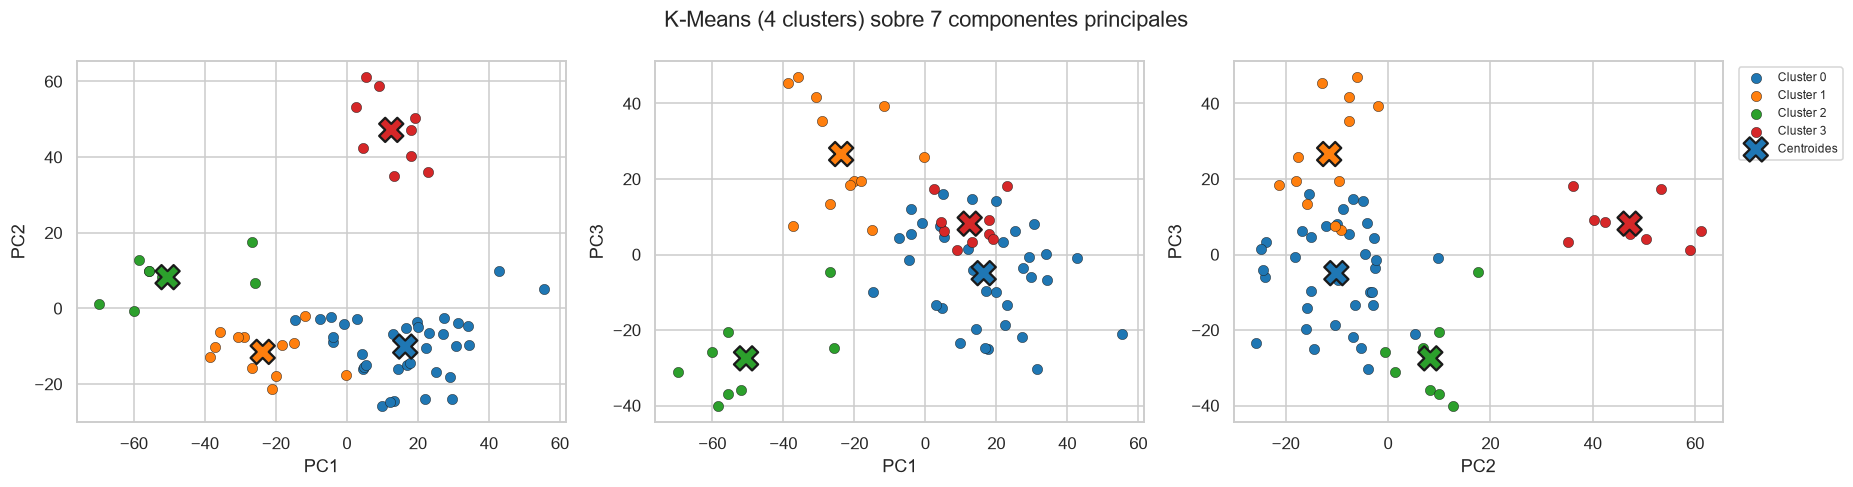

Observaciones por cluster: [35 12  8  9]


In [34]:
n_pc = 7
X_pca = scores[:, :n_pc]

km_pca = KMeans(n_clusters=4, n_init=50, random_state=0).fit(X_pca)
cl_km = km_pca.labels_

graficar_pares(X_pca, cl_km, [f'PC{i}' for i in range(1, n_pc + 1)],
               'K-Means (4 clusters) sobre 7 componentes principales', km_pca.cluster_centers_)
print('Observaciones por cluster:', np.bincount(cl_km))

**¿Qué indica?**

- Ahora los clusters sí se ven como regiones distinguibles. Los tres grupos que identificamos en las gráficas de componentes (el de la izquierda en PC1, el de arriba en PC2 y el de arriba en PC3) quedaron cada uno en su propio cluster, y la nube central forma el cuarto.
- En algunos pares de componentes dos clusters se ven encimados y en otros separados. Es normal, pues el algoritmo agrupa usando los 7 componentes y cada gráfica muestra solo 2.

## 2.5 Interpretación

### Tabla de clases vs clusters

Ahora sí usamos las etiquetas, pero **solo para interpretar**. La tabla muestra la cantidad de observaciones de cada clase (tipo de cáncer) en cada cluster.

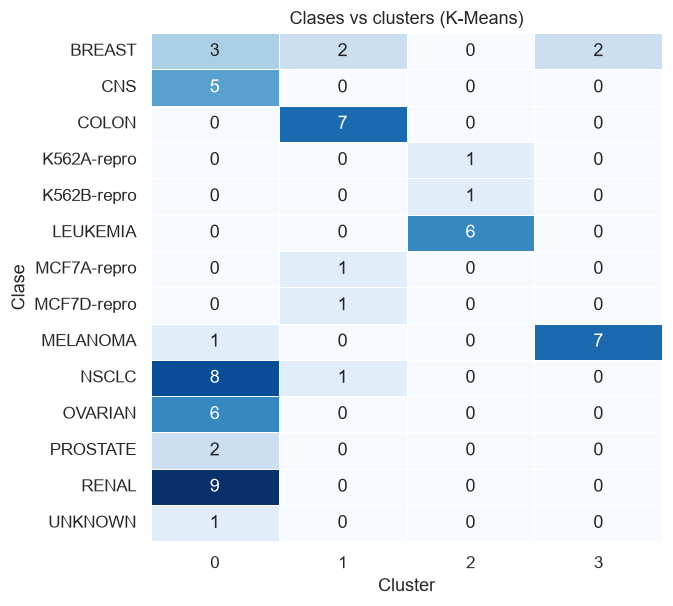

In [35]:
tabla = pd.crosstab(etiquetas, cl_km, rownames=['Clase'], colnames=['Cluster'])

plt.figure(figsize=(6, 6))
sns.heatmap(tabla, annot=True, fmt='d', cmap='Blues', cbar=False, linewidths=0.5)
plt.title('Clases vs clusters (K-Means)'); plt.show()

**¿Qué indica la tabla?** 

(Los números de los clusters son arbitrarios y podrían salir en otro orden, por ejemplo, si se usa otra seed; lo que importa es qué contiene cada uno.)

- **LEUKEMIA**: sus 6 observaciones quedan en un mismo cluster, junto con `K562A-repro` y `K562B-repro`, y nada más.
- **MELANOMA**: 7 de sus 8 observaciones quedan juntas en otro cluster.
- **COLON**: sus 7 observaciones quedan en un mismo cluster, junto con `MCF7A-repro` y `MCF7D-repro`.
- **BREAST** es la clase más dispersa: aparece repartida en tres clusters.
- El cluster más grande reúne a la mayoría de **RENAL, OVARIAN, CNS, NSCLC y PROSTATE**.

Sin usar las etiquetas, K-Means formó clusters en los que varias clases quedan prácticamente completas. Con 4 clusters no es posible separar las 14 etiquetas, así que algunas clases comparten cluster.

### Heatmap de los genes más relevantes

Para ver qué genes distinguen a los grupos, seleccionamos **solo 2 clusters** y seguimos estos pasos:

1. Correr K-Means con 2 clusters sobre los 7 componentes.
2. Calcular la expresión promedio de cada gen en cada cluster (con los datos originales, para poder hablar de genes y no de componentes).
3. Calcular la diferencia absoluta entre clusters para cada gen.
4. Seleccionar los **40 genes** con mayor diferencia entre clusters.
5. Estandarizar los datos, para que todos los genes estén en la misma escala de color.
6. Agrupar las observaciones por cluster.
7. Graficar el heatmap.

Observaciones por cluster: [19 45]
Cluster      0  1
Clase            
BREAST       2  5
CNS          0  5
COLON        7  0
K562A-repro  1  0
K562B-repro  1  0
LEUKEMIA     6  0
MCF7A-repro  1  0
MCF7D-repro  1  0
MELANOMA     0  8
NSCLC        0  9
OVARIAN      0  6
PROSTATE     0  2
RENAL        0  9
UNKNOWN      0  1


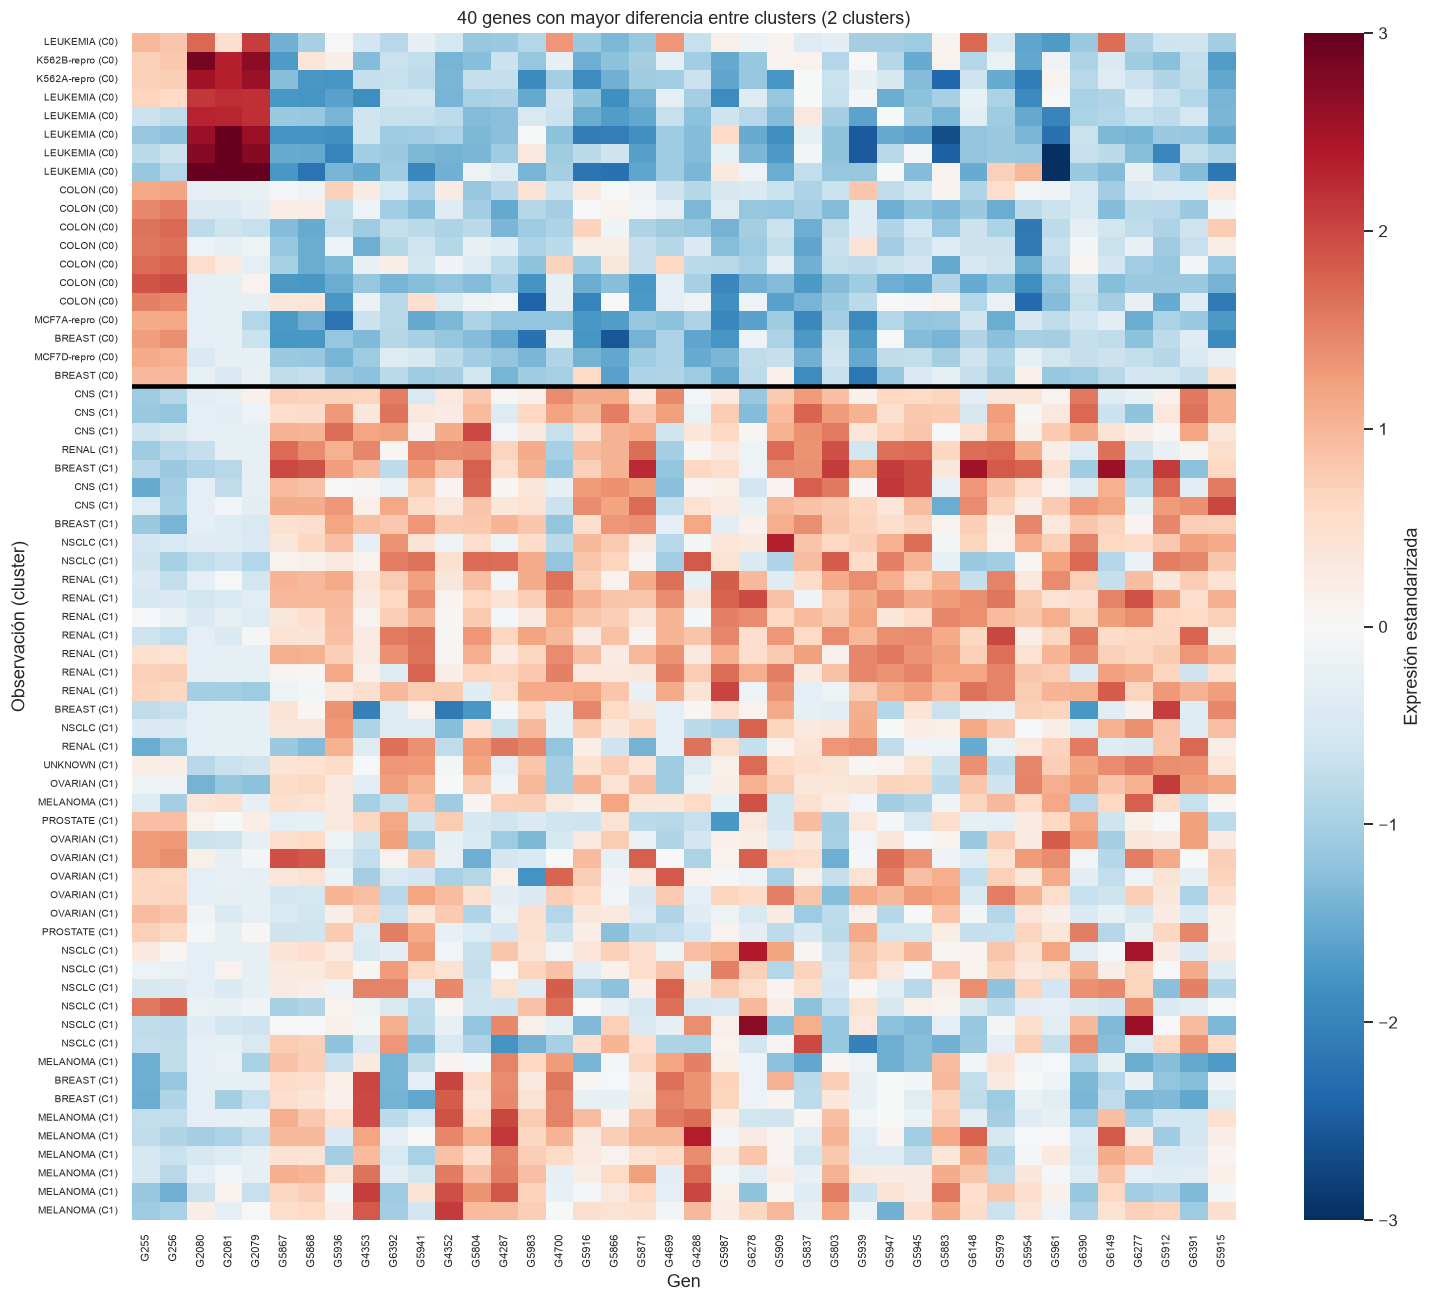

In [36]:
km2 = KMeans(n_clusters=2, n_init=50, random_state=0).fit(X_pca)
cl2 = km2.labels_
print('Observaciones por cluster:', np.bincount(cl2))
print(pd.crosstab(etiquetas, cl2, rownames=['Clase'], colnames=['Cluster']))

medias = pd.DataFrame(datos).groupby(cl2).mean()                 # expresión promedio por cluster
diferencia = (medias.loc[0] - medias.loc[1]).abs()                # diferencia absoluta por gen
top_genes = diferencia.sort_values(ascending=False).index[:40]    # 40 genes con mayor diferencia

z = StandardScaler().fit_transform(datos[:, top_genes])           # estandarizar
orden = np.argsort(cl2, kind='stable')                            # agrupar por cluster
z_df = pd.DataFrame(z[orden], columns=[f'G{g}' for g in top_genes],
                    index=[f'{etiquetas[i]} (C{cl2[i]})' for i in orden])

mas_en_0 = (medias.loc[0, top_genes] > medias.loc[1, top_genes]).to_numpy()
z_df = z_df.iloc[:, np.argsort(~mas_en_0, kind='stable')]         # genes más altos en el cluster 0 primero

plt.figure(figsize=(14, 12))
ax = sns.heatmap(z_df, cmap='RdBu_r', center=0, vmin=-3, vmax=3,
                 cbar_kws={'label': 'Expresión estandarizada'}, yticklabels=True)
ax.axhline((cl2 == 0).sum(), color='black', lw=3)
ax.tick_params(axis='y', labelsize=6.5); ax.tick_params(axis='x', labelsize=7)
plt.title('40 genes con mayor diferencia entre clusters (2 clusters)')
plt.xlabel('Gen'); plt.ylabel('Observación (cluster)')
plt.tight_layout(); plt.show()

**¿Qué indica?**

- Con 2 clusters se separa un grupo de 19 observaciones (**LEUKEMIA**, las **K562**, **COLON**, las **MCF7** y 2 de **BREAST**) de las otras 45 (RENAL, OVARIAN, CNS, NSCLC, PROSTATE, MELANOMA y el resto de BREAST).
- En el heatmap, la línea negra marca la frontera entre clusters y coincide con un **cambio claro de patrón**. La mayoría de los 40 genes tienen expresión baja (azul) en el cluster pequeño y alta (rojo) en el grande. Solo unos pocos genes, a la izquierda, van en sentido contrario.
- Dentro del cluster pequeño se ven dos bloques, unos genes tienen expresión muy alta solo en LEUKEMIA y otros solo en COLON. Es decir, ese cluster reúne dos clases distintas que tienen en común, sobre todo, la expresión baja de los genes que caracterizan al otro cluster. Con 4 clusters, estas dos clases quedaban separadas.
- Estos genes son los que más contribuyen a distinguir los clusters, y serían el punto de partida para estudiar qué caracteriza a cada grupo.

<div style="page-break-before: always;"></div>

---
# Parte 3 · Hierarchical clustering con NCI60

## 3.1 Dataset y preprocesamiento

Usamos el mismo dataset NCI60 y el mismo preprocesamiento de la Parte 2, datos estandarizados, PCA y los **primeros 7 componentes principales**, elegidos con la gráfica de varianza explicada de la sección 2.3.

Graficamos PC1 vs PC2, ahora coloreando cada observación por su clase.

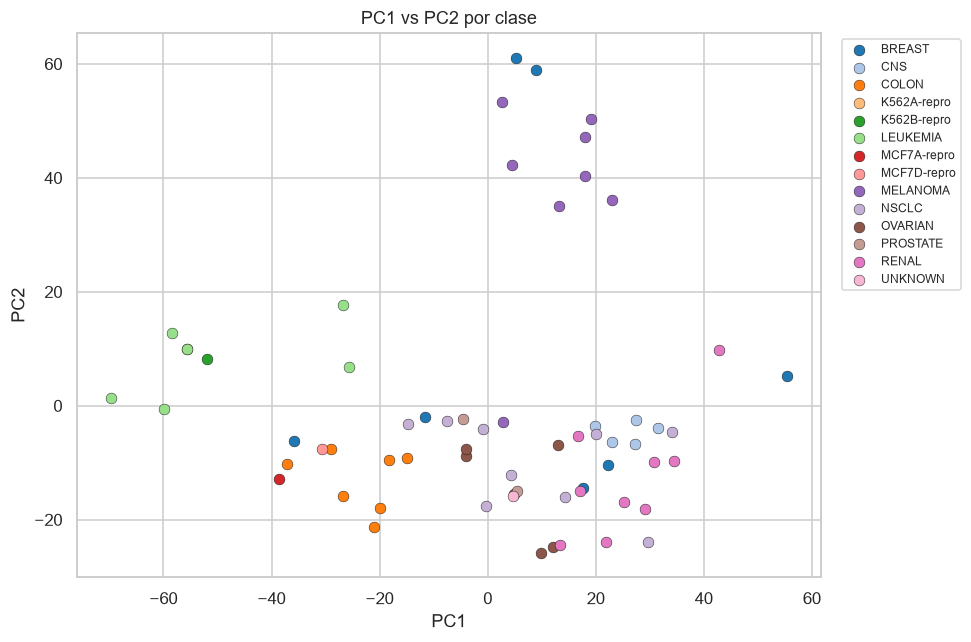

In [37]:
nci = load_data('NCI60')
datos = nci['data']
etiquetas = nci['labels']['label']

X_pca = PCA().fit_transform(StandardScaler().fit_transform(datos))[:, :7]

tipos = sorted(etiquetas.unique())
pal_tipos = dict(zip(tipos, sns.color_palette('tab20', len(tipos))))

plt.figure(figsize=(9, 6))
for t in tipos:
    m = (etiquetas == t).to_numpy()
    plt.scatter(X_pca[m, 0], X_pca[m, 1], s=50, color=pal_tipos[t], label=t, edgecolor='k', linewidth=0.3)
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
plt.title('PC1 vs PC2 por clase'); plt.tight_layout(); plt.show()

**¿Estamos seguros de que seleccionamos el número correcto de clusters?**

Coloreando por clase se ve que algunas forman grupos compactos (LEUKEMIA a la izquierda, MELANOMA arriba), pero otras se encuentran encimadas en la nube central (RENAL, NSCLC, OVARIAN, BREAST, CNS). No hay una frontera clara que indique que son exactamente 4 grupos: también podrían defenderse 3 o 5.

K-Means obliga a elegir ese número **antes** de agrupar. El hierarchical clustering no lo necesita, como veremos a continuación.

## 3.2 Hierarchical clustering: *complete* y euclidiana

Realizamos un proceso de hierarchical clustering con la librería `scipy`:

- Método (linkage): `'complete'`
- Métrica: `'euclidean'`

Graficamos el resultado como un **dendrograma**, etiquetando cada hoja con la clase de la observación para poder interpretarlo.

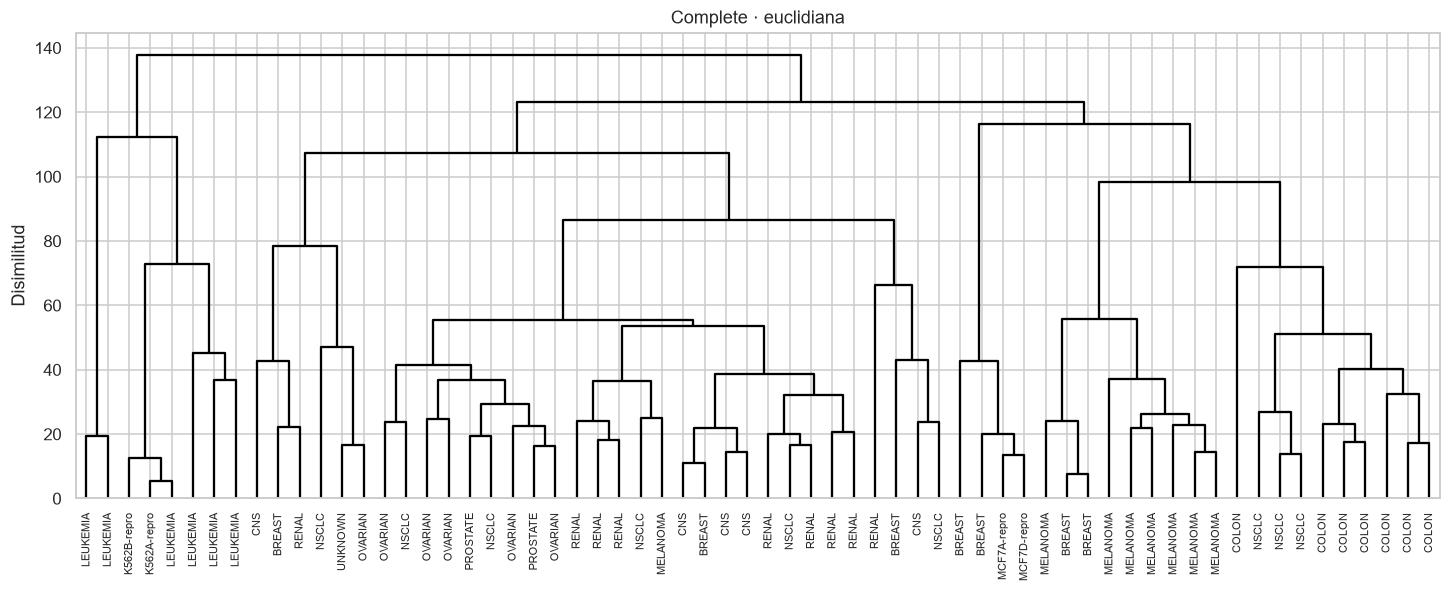

In [38]:
def graficar_dendrograma(Z, titulo, umbral=None, ax=None):
    ax = ax or plt.figure(figsize=(16, 5.5)).gca()
    dendrogram(Z, labels=etiquetas.to_numpy(), ax=ax, leaf_font_size=7,
               color_threshold=-np.inf if umbral is None else umbral,   # -inf = monocromático
               above_threshold_color='black')
    if umbral is not None:
        ax.axhline(umbral, ls='--', c='red')
    ax.set_title(titulo); ax.set_ylabel('Disimilitud')
    return ax

Z_comp_eu = linkage(X_pca, method='complete', metric='euclidean')
graficar_dendrograma(Z_comp_eu, 'Complete · euclidiana')
plt.show()

## 3.3 Dendrograma

**¿Cómo se lee?**

- Cada **hoja** (en la parte de abajo) representa una observación.
- Conforme subimos por el árbol, las hojas se unen en **ramas**. Se unen las observaciones que son similares entre sí.
- **Entre más abajo es la unión, más similares son** las observaciones o grupos de observaciones.
- El eje *y* representa la **disimilitud**.

**¿Qué muestra este dendrograma?**

- La unión más alta separa a las observaciones de **LEUKEMIA** (con las K562) del resto, es decir, son el grupo más diferente de todos. Coincide con el grupo aislado a la izquierda en PC1 vs PC2.
- **MELANOMA** y **COLON** forman sus propias ramas, que se unen a alturas bajas o medias.
- Las observaciones `K562A-repro` y `K562B-repro` se unen casi en la parte más baja del árbol, igual que `MCF7A-repro` y `MCF7D-repro`. Son las observaciones más similares entre sí de todo el dataset.
- RENAL, OVARIAN, CNS, NSCLC y PROSTATE aparecen mezcladas en una rama grande, lo que coincide con lo encimadas que estaban en PC1 vs PC2.

## 3.4 Dendrograma policromático: 2, 3 y 4 clusters

Volvemos a generar el dendrograma, ahora policromático. El parámetro `color_threshold` define una altura de corte: cada rama que queda por debajo de esa altura recibe un color distinto, y cada color es un cluster. Cambiamos el threshold a diferentes valores para generar 2, 3 y 4 clusters.

Para obtener exactamente $k$ clusters, el threshold debe quedar entre las alturas de dos uniones consecutivas del árbol. La función `threshold_para_k` toma el punto medio entre ellas (la tercera columna de `Z` guarda la altura de cada unión).

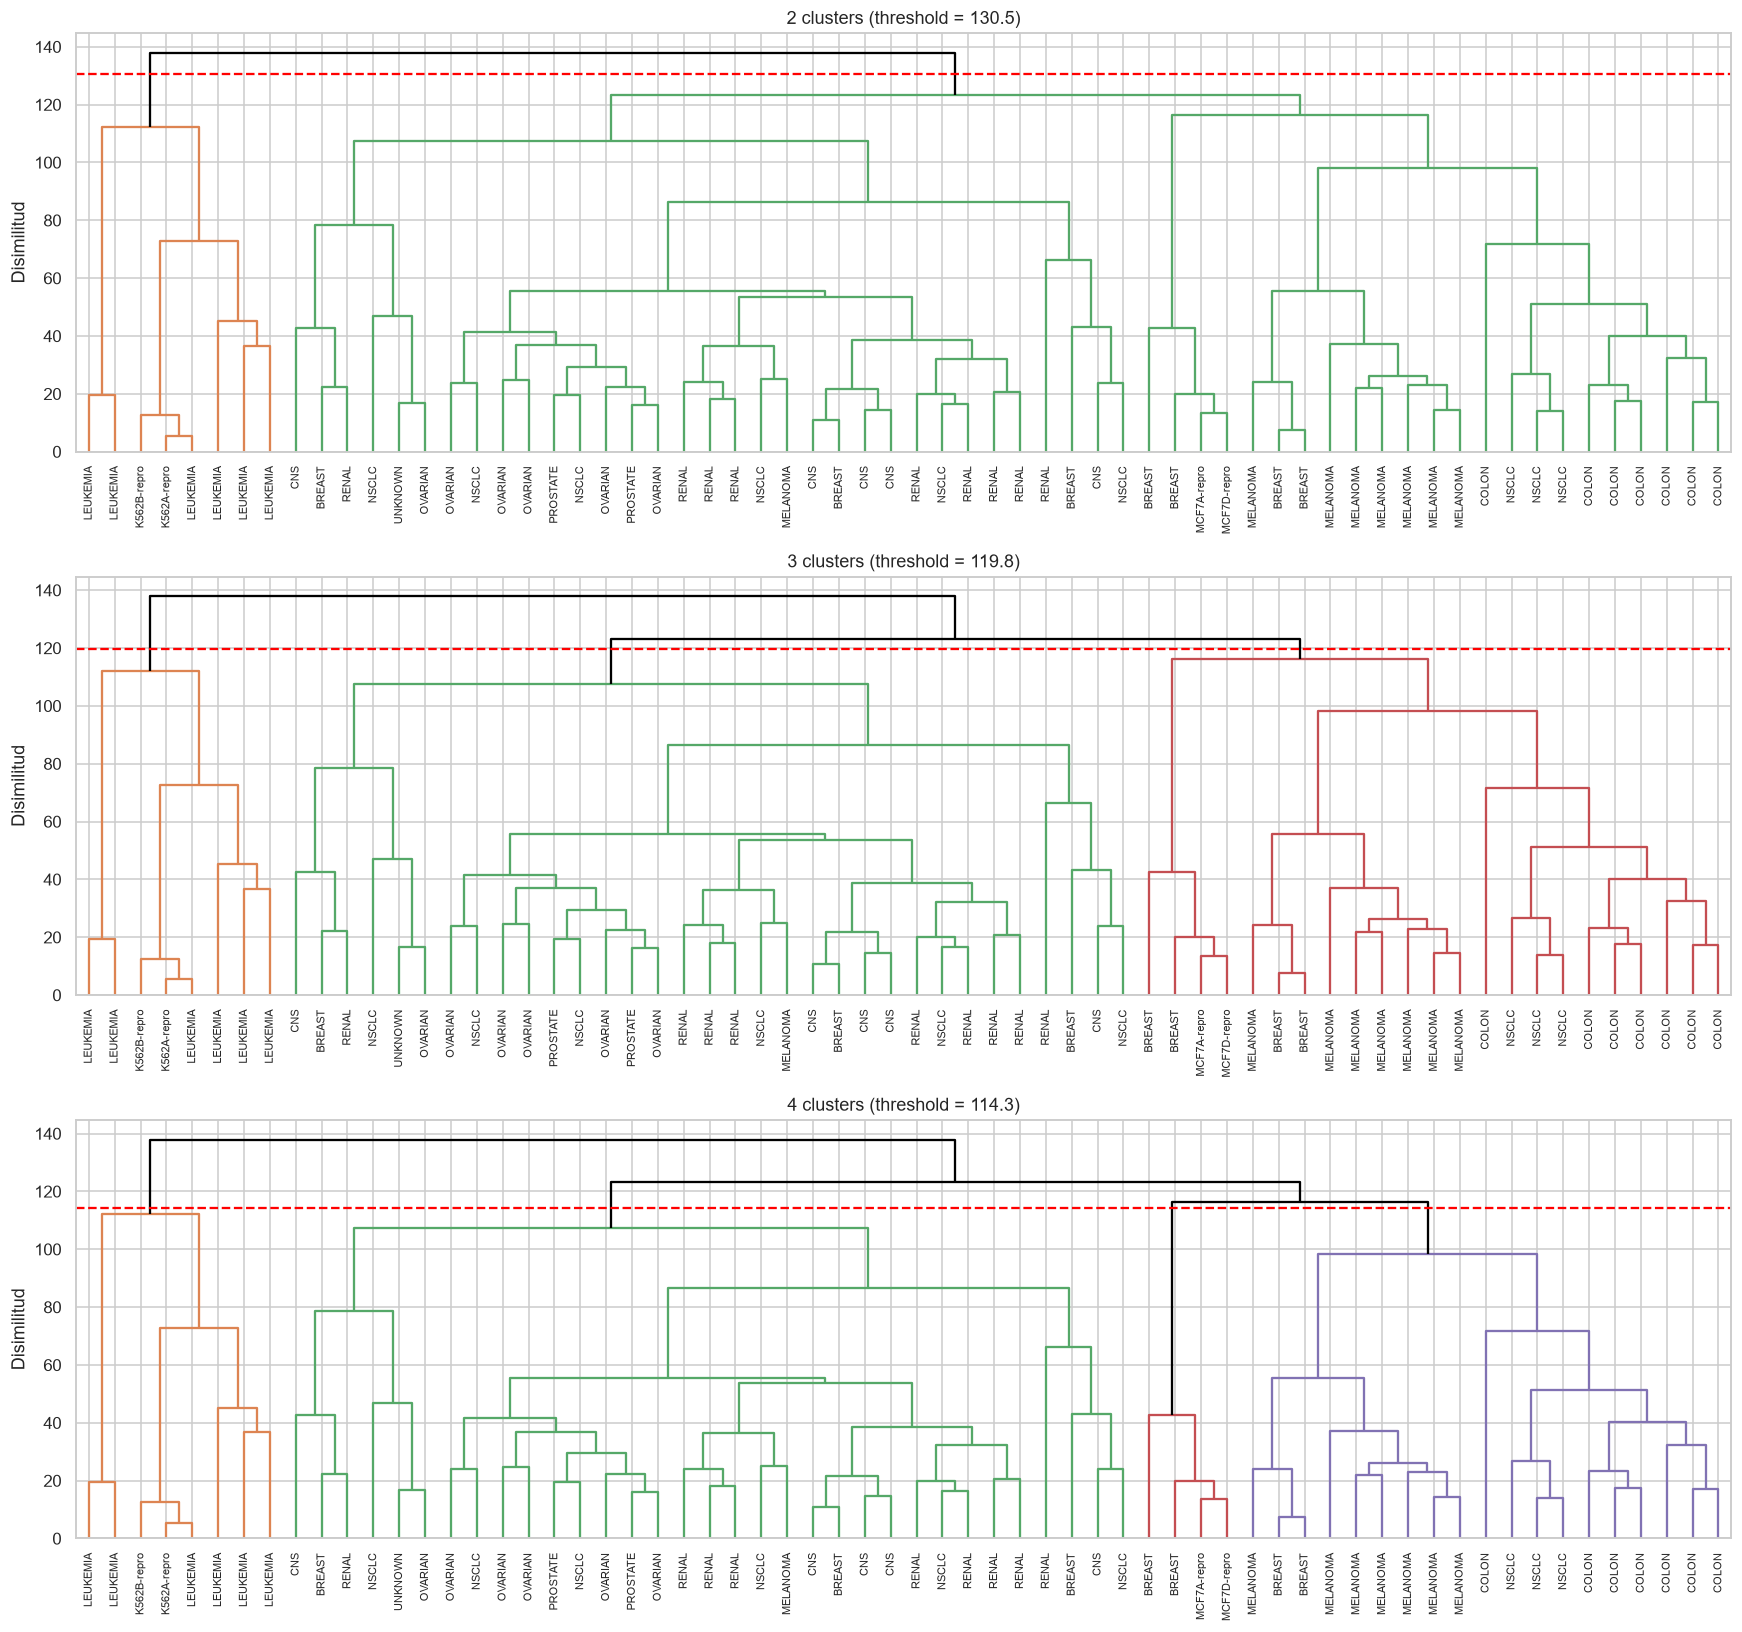

In [39]:
def threshold_para_k(Z, k):
    return (Z[-k, 2] + Z[-(k - 1), 2]) / 2

fig, axs = plt.subplots(3, 1, figsize=(16, 15))
for ax, k in zip(axs, [2, 3, 4]):
    t = threshold_para_k(Z_comp_eu, k)
    graficar_dendrograma(Z_comp_eu, f'{k} clusters (threshold = {t:.1f})', t, ax)
plt.tight_layout(); plt.show()

**¿Qué indica?**

- **2 clusters:** LEUKEMIA (con las K562) contra todas las demás observaciones.
- **3 clusters:** el grupo grande se divide en dos: una rama con MELANOMA, COLON, las MCF7 y algunas de BREAST y NSCLC, y otra con las clases mezcladas de la nube central.
- **4 clusters:** de la rama de MELANOMA y COLON se separa un grupo pequeño (las MCF7 y dos de BREAST).

En cada paso, uno de los clusters existentes se divide en dos y los demás quedan igual.

## 3.5 Teoría: altura de corte, jerarquía y algoritmo

**La altura a la que se corta el árbol determina la cantidad de clusters.**

- K-Means necesita un valor de $k$ antes de empezar.
- El hierarchical clustering genera un dendrograma que representa todos los posibles clusters, desde 1 hasta $n$.
- Típicamente, la cantidad de clusters se selecciona a partir del dendrograma generado.

**¿Por qué "jerárquico"?** Porque todos los clusters que se generan al cortar el dendrograma a cierta altura están **anidados** en los clusters que se generarían al cortarlo más arriba. Es justo lo que vimos al pasar de 2 a 3 y a 4 clusters.

**Desventaja:** los clusters reales no necesariamente están anidados. Por ejemplo, en una población de 3 países distintos con 2 tipos de profesión, la mejor división en 2 clusters podría ser por profesión y la mejor en 3 por país. Los 3 clusters por país no estarían anidados dentro de los 2 clusters por profesión, y el hierarchical clustering no puede representar eso.

### Algoritmo

1. Se inicia con $n$ observaciones y se calcula una métrica de disimilitud entre todos los pares de observaciones. Cada observación se considera su propio cluster.
2. Para $i = n, n-1, \dots, 2$:
   - **a)** Se identifica el par de clusters con menor disimilitud (mayor similitud).
   - **b)** Se unen ambos clusters en una misma rama. Su métrica de disimilitud indica la altura a la que se muestran en el dendrograma.
   - **c)** Se actualizan las métricas de disimilitud utilizando los $i-1$ clusters restantes.

## 3.6 Métrica de correlación

Realizamos un nuevo proceso de hierarchical clustering con el mismo método, pero cambiando la métrica:

- Método: `'complete'`
- Métrica: `'correlation'`

Graficamos el dendrograma monocromático y lo comparamos con el anterior.

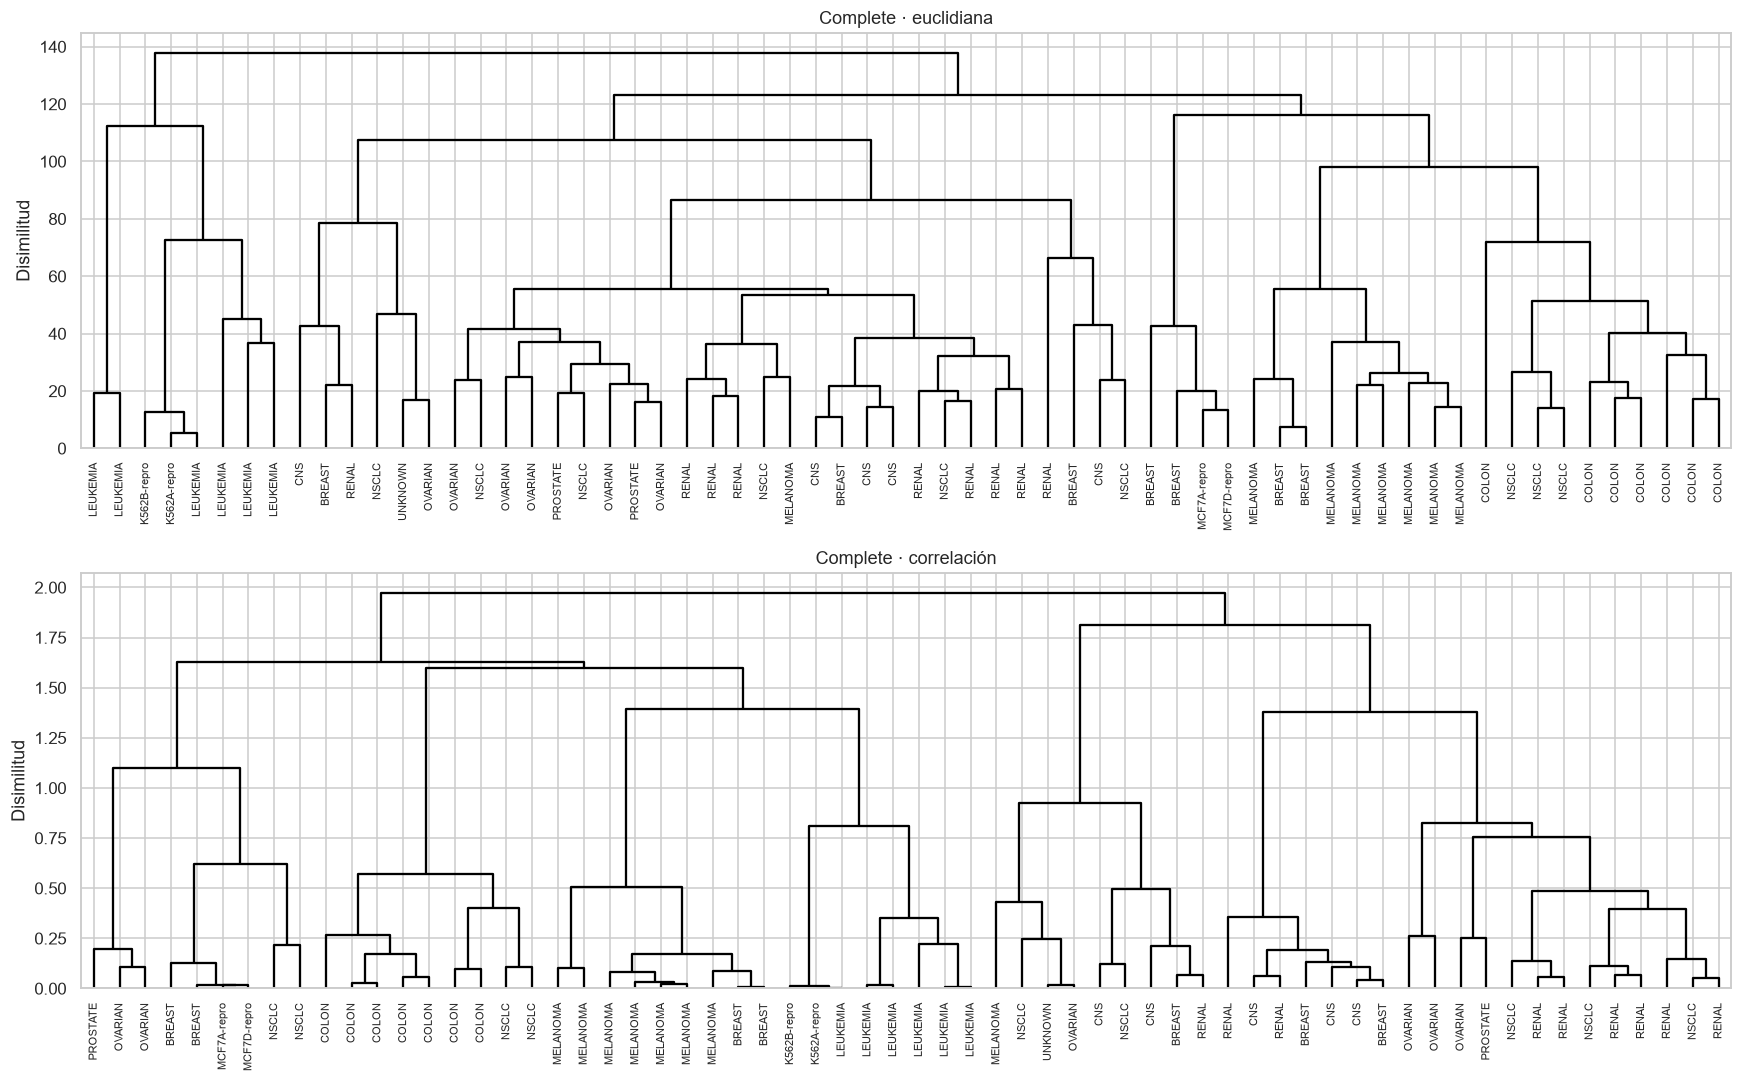

In [40]:
Z_comp_cor = linkage(X_pca, method='complete', metric='correlation')

fig, axs = plt.subplots(2, 1, figsize=(16, 10))
graficar_dendrograma(Z_comp_eu, 'Complete · euclidiana', ax=axs[0])
graficar_dendrograma(Z_comp_cor, 'Complete · correlación', ax=axs[1])
plt.tight_layout(); plt.show()

**¿Qué indica la comparación?**

- La **escala** del eje *y* cambia por completo, porque la disimilitud ahora se mide de otra forma.
- La **estructura** del árbol también cambia: las ramas grandes se organizan diferente y las clases de la nube central quedan agrupadas de otra manera. Elegir otra métrica produce otros clusters.
- Aun así, **LEUKEMIA, MELANOMA y COLON** siguen formando cada una su propia rama, y las observaciones `-repro` siguen uniéndose muy abajo. Los grupos que aparecen con ambas métricas son los más claros del dataset.

## 3.7 Teoría: métricas de disimilitud

La distancia euclidiana agrupa observaciones con valores de magnitud parecida, mientras que la correlación agrupa observaciones con un patrón parecido. Esto explica por qué los dos dendrogramas de la sección anterior son diferentes.

## 3.8 Método *average*

Realizamos un nuevo proceso de hierarchical clustering, ahora cambiando el método:

- Método: `'average'`
- Métrica: `'euclidean'`

Graficamos el dendrograma monocromático y lo comparamos con los dos anteriores.

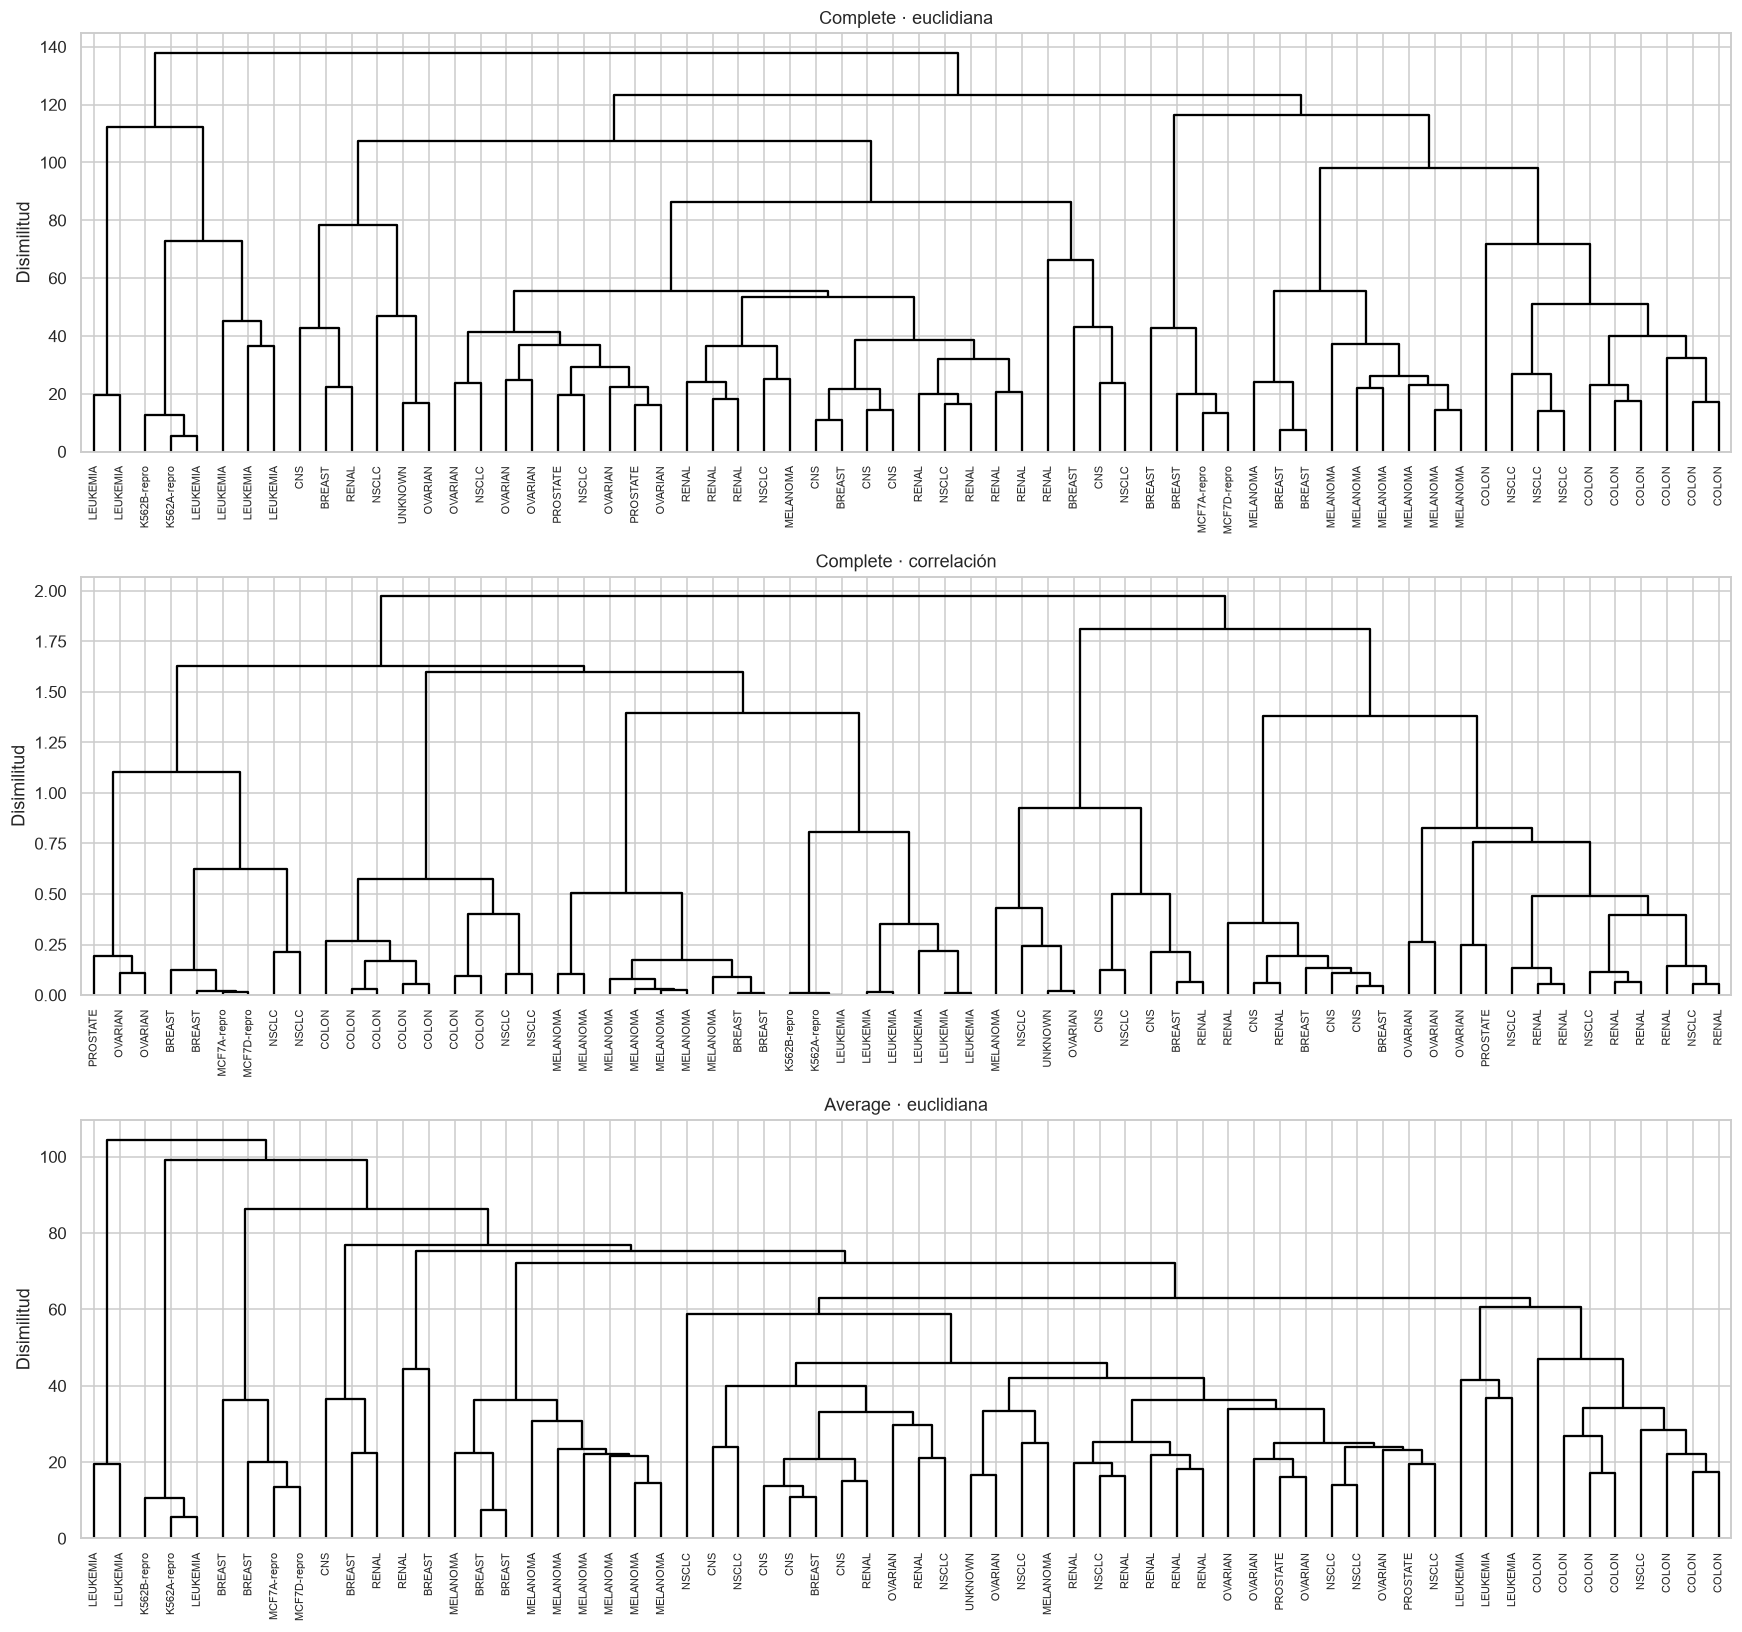

In [41]:
Z_avg_eu = linkage(X_pca, method='average', metric='euclidean')

fig, axs = plt.subplots(3, 1, figsize=(16, 15))
graficar_dendrograma(Z_comp_eu, 'Complete · euclidiana', ax=axs[0])
graficar_dendrograma(Z_comp_cor, 'Complete · correlación', ax=axs[1])
graficar_dendrograma(Z_avg_eu, 'Average · euclidiana', ax=axs[2])
plt.tight_layout(); plt.show()

**¿Qué indica la comparación?**

- Con *average* el árbol es mucho más **desbalanceado**, la mayoría de las observaciones se van uniendo poco a poco a una misma rama grande, y solo unos grupos pequeños quedan separados hasta arriba. Si lo cortáramos en pocos clusters, uno concentraría casi todas las observaciones.
- Con *complete* las ramas tienen tamaños más parejos y los grupos (LEUKEMIA, MELANOMA, COLON) se distinguen con más claridad.
- Las alturas también son menores con *average*. Al promediar las disimilitudes entre clusters, el valor siempre es menor o igual que la disimilitud más grande, que es la que usa *complete*.

## 3.9 Teoría: métodos de linkage

Comparar una observación con otra es trivial, pues es un valor específico de la métrica de disimilitud. Cuando se comparan múltiples observaciones con múltiples observaciones (un cluster contra otro) hay múltiples valores de disimilitud, y hay que decidir cuál usar. Eso es lo que define el método de linkage. Los más comunes son:

| Método | Cómo calcula la disimilitud entre los clusters A y B |
|---|---|
| **Complete** | Se obtienen todas las disimilitudes entre observaciones del cluster A contra observaciones del cluster B y se utiliza la **más grande**. |
| **Single** | Mismo proceso, pero se utiliza la disimilitud más pequeña. |
| **Average** | Mismo proceso, pero se calcula el promedio de las disimilitudes. |
| **Ward** | Minimiza el incremento en la variación dentro del grupo (*within-cluster variation*) al unir clusters. Solo se usa con distancia euclidiana. |

Esto explica las diferencias de la sección 3.8. *Complete* usa la disimilitud más grande, así que solo une dos clusters cuando **todas** sus observaciones están relativamente cerca, y forma grupos compactos y parejos. *Average* usa el promedio, así que un cluster grande puede seguir absorbiendo observaciones aunque algunas queden lejos de otras.

<div style="page-break-before: always;"></div>


---
# Parte 4 · K-Means vs hierarchical clustering

## 4.1 Comparación de resultados en NCI60

Para comparar ambos métodos en igualdad de condiciones, tomamos las dos soluciones de 4 clusters sobre los mismos 7 componentes principales:

- **K-Means** con 4 clusters (sección 2.4).
- **Hierarchical clustering** con método *complete* y distancia euclidiana, cortando el dendrograma en 4 clusters (sección 3.4).

La función `fcluster` de `scipy` corta el dendrograma y devuelve la etiqueta de cada observación (`criterion='maxclust'` indica que queremos exactamente 4 clusters). Comparamos ambas particiones con dos tablas: K-Means contra hierarchical, y clase contra hierarchical.

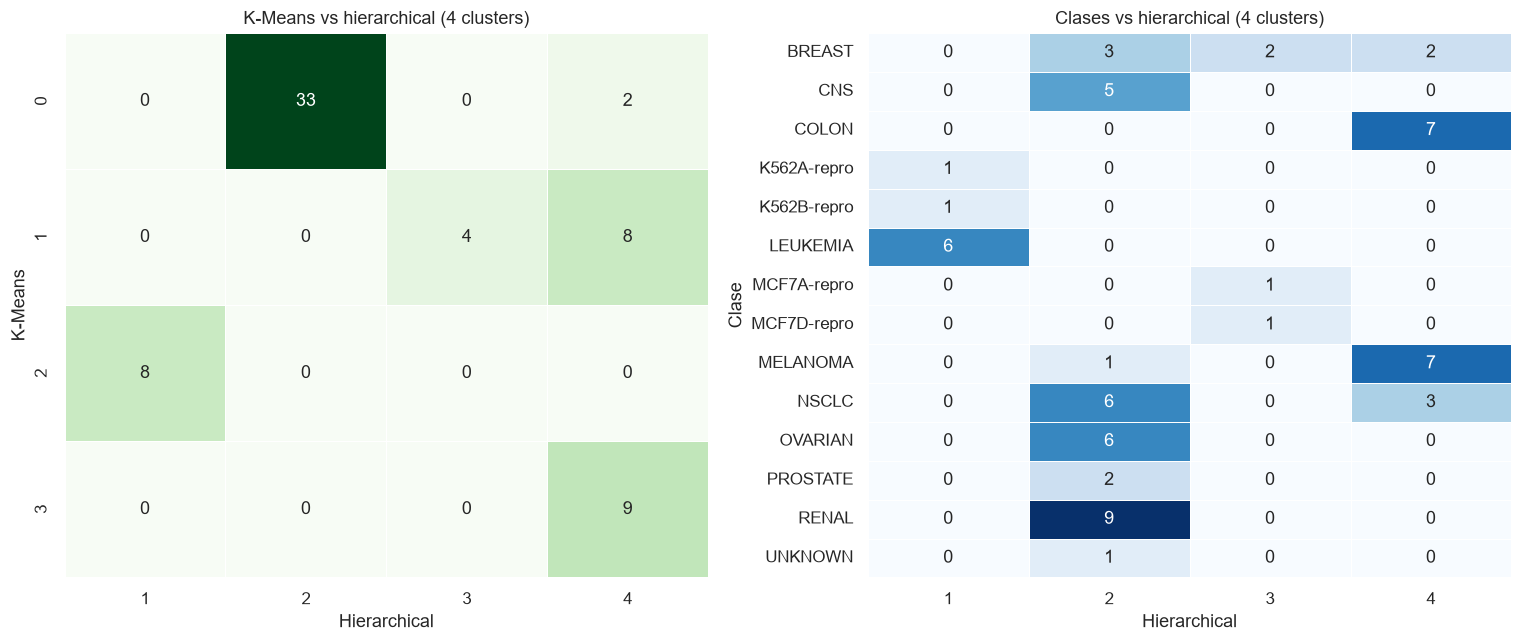

Observaciones por cluster · K-Means:      [35 12  8  9]
Observaciones por cluster · Hierarchical: [ 8 33  4 19]


In [42]:
from scipy.cluster.hierarchy import fcluster

cl_hc = fcluster(Z_comp_eu, 4, criterion='maxclust')

fig, axs = plt.subplots(1, 2, figsize=(14, 6))
sns.heatmap(pd.crosstab(cl_km, cl_hc, rownames=['K-Means'], colnames=['Hierarchical']),
            annot=True, fmt='d', cmap='Greens', cbar=False, linewidths=0.5, ax=axs[0])
axs[0].set_title('K-Means vs hierarchical (4 clusters)')
sns.heatmap(pd.crosstab(etiquetas, cl_hc, rownames=['Clase'], colnames=['Hierarchical']),
            annot=True, fmt='d', cmap='Blues', cbar=False, linewidths=0.5, ax=axs[1])
axs[1].set_title('Clases vs hierarchical (4 clusters)')
plt.tight_layout(); plt.show()

print('Observaciones por cluster · K-Means:     ', np.bincount(cl_km))
print('Observaciones por cluster · Hierarchical:', np.bincount(cl_hc)[1:])

**¿Qué indica?** 

- **Coinciden en lo principal.** El cluster de LEUKEMIA (con las K562) es idéntico en ambos métodos, y el cluster grande de la nube central (RENAL, OVARIAN, CNS, NSCLC, PROSTATE) es prácticamente el mismo: 35 observaciones en K-Means y 33 en hierarchical.
- **Difieren en MELANOMA y COLON.**
  - **K-Means** los separa en dos clusters distintos.
  - **Hierarchical** los junta en una sola rama de 19 observaciones y, como cuarto cluster, separa un grupo pequeño de 4 (las MCF7 y dos de BREAST).
- **La causa es la estructura anidada.** Al cortar en 3 clusters, el dendrograma ya tenía a MELANOMA y COLON en la misma rama (sección 3.4), y el cuarto cluster solo puede salir de dividir una rama existente. 

Que dos métodos con funcionamientos distintos encuentren los mismos grupos (LEUKEMIA y la nube central) indica que esos grupos son una estructura real de los datos, no un efecto del algoritmo.

## 4.2 Ventajas y desventajas

| Aspecto | K-Means | Hierarchical clustering |
|---|---|---|
| **Número de clusters** | Hay que fijarlo antes de correr el algoritmo. | No hay que fijarlo: el dendrograma contiene todas las opciones (de 1 a $n$) y se elige después, según la altura de corte. |
| **Resultado** | Estocástico: depende de la asignación inicial y puede caer en un óptimo local. Necesita `n_init`. | Determinista: con los mismos datos, método y métrica, el árbol siempre es el mismo. |
| **Estructura de los clusters** | Cada valor de $K$ se resuelve de forma independiente, así que los clusters **no** tienen que estar anidados. | Los clusters siempre están anidados, aunque la estructura real no lo esté. |
| **Decisiones que hay que tomar** | El número de clusters y `n_init`. | El método de linkage y la métrica de disimilitud, que cambian mucho el resultado (secciones 3.6 y 3.8). |
| **Métrica** | Usa distancia euclidiana al cuadrado (y por eso usa medias como centroides). | Acepta cualquier métrica de disimilitud (euclidiana, correlación, etc.). |
| **Interpretación** | Se describe cada cluster con su centroide (el perfil promedio). | El dendrograma muestra qué tan parecidas son las observaciones y en qué orden se agrupan. |
| **Costo computacional** | Cada iteración compara cada observación contra $K$ centroides: crece de forma aproximadamente lineal con $n$. | Necesita la disimilitud entre todos los pares de observaciones: crece con $n^2$ en tiempo y memoria. |

## 4.3 ¿Cuándo usar cada uno?

Ninguno es mejor en todos los casos, cada uno es mejor bajo ciertas condiciones.

**K-Means es mejor cuando:**

- **Hay muchas observaciones** (miles o millones). Calcular todos los pares que necesita el hierarchical clustering se vuelve impráctico.
- **Se conoce o se puede justificar el número de clusters**, por ejemplo cuando un negocio necesita exactamente 3 segmentos de clientes.
- **Los grupos son compactos y de tamaño parecido**, como las tres nubes del dataset sintético.

**Hierarchical clustering es mejor cuando:**

- **No se sabe cuántos clusters hay**, como en NCI60. El dendrograma permite explorar todas las opciones antes de decidir.
- **Hay pocas observaciones** (decenas o cientos), así que calcular todos los pares no es un problema.
- **Interesa la relación entre observaciones**, no solo la partición final, también qué observaciones son más parecidas y qué grupos están contenidos en otros.
- **Se necesita otra métrica distinta a la euclidiana**, como la correlación, cuando importa el patrón y no la magnitud.
- **Se necesita un resultado reproducible** sin depender de semillas ni de múltiples inicializaciones.

**En NCI60** el hierarchical clustering tiene ventaja, pues con solo 64 observaciones su costo no es problema, el número de clusters no es claro (sección 3.1) y el dendrograma mostró información que K-Means no da, como que LEUKEMIA es el grupo más diferente de todos.

## 4.4 ¿Cómo deberían implementarse?

**Pasos comunes a ambos métodos**

1. **Estandarizar** las variables cuando están en escalas distintas, para que ninguna domine la distancia solo por tener valores más grandes.
2. Cuando hay muchas variables, **reducir la dimensión con PCA** y elegir el número de componentes con la varianza explicada. En NCI60 esto fue lo que permitió visualizar e interpretar los clusters.
3. **Interpretar** los clusters al final, con etiquetas conocidas (tabla de clases vs clusters) o con el perfil de cada grupo (heatmap de las variables que más los distinguen).

**K-Means**

1. Elegir el número de clusters a partir de la visualización de los datos (por ejemplo, gráficas de componentes principales) o de un dendrograma previo.
2. Correr el algoritmo varias veces desde asignaciones iniciales distintas (`n_init` entre 10 y 50) y quedarse con la solución de **menor variación dentro de los grupos**.
3. Fijar una **semilla** (`random_state`) para que el resultado sea reproducible.

**Hierarchical clustering**

1. Elegir la **métrica** según lo que interese comparar, **euclidiana** si importa la magnitud y **correlación** si importa el patrón.
2. Elegir el **método de linkage**, *complete* (o *average*) como opción general; *Ward* si se quiere el mismo criterio que K-Means (minimizar la variación dentro de los grupos), solo con distancia euclidiana.
3. Graficar el **dendrograma** y elegir la altura de corte, idealmente donde las uniones dan un salto grande de altura, ya que eso indica grupos bien diferenciados.
4. Probar **más de una combinación** de método y métrica. Los grupos que se mantienen en todas (como LEUKEMIA, MELANOMA y COLON en NCI60) son los más confiables.

<div style="page-break-before: always;"></div>

---
# Conclusiones

1. K-Means busca la partición con la menor variación dentro de los grupos. Su algoritmo alterna dos pasos (calcular centroides y asignar cada observación al centroide más cercano) hasta que las asignaciones dejan de cambiar.
2. El algoritmo encuentra un óptimo local que depende de la asignación aleatoria inicial: en el dataset sintético, una de seis inicializaciones terminó en una solución mucho peor. Por eso se corre múltiples veces (`n_init`) y se elige la solución con el objetivo más pequeño.
3. En NCI60, con 6,830 variables, aplicar K-Means directamente produce clusters que no se pueden visualizar ni interpretar. El preprocesamiento con PCA resume los datos en 7 componentes, donde los grupos sí se distinguen.
4. Al interpretar los clusters con las etiquetas, varias clases quedaron prácticamente completas en un mismo cluster (LEUKEMIA, MELANOMA, COLON), mientras que otras (BREAST, y las de la nube central) quedaron repartidas o mezcladas.
5. El hierarchical clustering no necesita fijar el número de clusters antes de empezar: el dendrograma representa todos los posibles clusters y la cantidad se elige según la altura de corte. A cambio, los clusters siempre quedan anidados.
6. El resultado del hierarchical clustering depende de la métrica de disimilitud (la euclidiana agrupa por magnitud y la correlación por patrón) y del método de linkage (*complete* produjo ramas más balanceadas que *average*). Los grupos que se mantienen al cambiar estas opciones, como LEUKEMIA, MELANOMA y COLON, son los más claros del dataset.

<div style="page-break-before: always;"></div>

---
# Referencias

Martínez Torteya, A. (2026a). *C3.3 K-Means clustering* [Diapositivas de PowerPoint]. Universidad de Monterrey.

Martínez Torteya, A. (2026b). *C3.4 Hierarchical clustering* [Diapositivas de PowerPoint]. Universidad de Monterrey.

